# Laboratorio 2
## Pipeline de Machine Learning para Clasificación de Sentimientos con Transformers

En este laboratorio, realizarás una clasificación de sentimiento de reseñas de películas mediante el modelo de transformadores. Como parte de este laboratorio, implementarás un análisis exploratorio de datos para obtener conocimientos sobre la data y su distribución. Posteriormente, los modelos requieren un tokenizer que implementarás personalmente. A continuación, programarás el elemento integral del modelo de transformador, la Mecánica de Atención. Finalmente, combinarás todo y entrenarás al modelo en la tarea de clasificación binaria.

## Tutorial: Cómo activar la GPU gratuita en Google Colab

Para este laboratorio, se recomienda usar la GPU gratuita de Google Colab para acelerar el entrenamiento. Sigue estos pasos:

### Pasos para activar la GPU:

1. **Abre tu notebook en Google Colab**
   - Sube este archivo a Google Drive
   - Haz clic derecho sobre el archivo → "Abrir con" → "Google Colaboratory"

2. **Cambia el tipo de entorno de ejecución**
   - En el menú superior, ve a: **Entorno de ejecución** → **Cambiar tipo de entorno de ejecución**
   - (O en inglés: **Runtime** → **Change runtime type**)

3. **Selecciona la GPU**
   - En "Acelerador por hardware" (Hardware accelerator), selecciona T4 GPU
   - Haz clic en **Guardar** (Save)

4. **Verifica que la GPU esté activa**
   - Ejecuta la siguiente celda para confirmar que tienes acceso a la GPU

### Notas importantes:
- La GPU gratuita tiene límites de uso diario (aproximadamente 12-15 horas por día)
- Si se desconecta, deberás volver a ejecutar todas las celdas
- Guarda tu progreso frecuentemente

In [1]:
# Verificar que la GPU está disponible
import torch
if torch.cuda.is_available():
    print(f"✓ GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"  Memoria total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("✗ No se detectó GPU. Por favor, activa la GPU siguiendo los pasos del tutorial anterior.")

✗ No se detectó GPU. Por favor, activa la GPU siguiendo los pasos del tutorial anterior.


## Instalación de Dependencias

Primero, instalaremos las bibliotecas necesarias para este laboratorio.

In [2]:
!pip install -q datasets

## Imports y Setup Inicial

Importamos todas las bibliotecas necesarias y configuramos las semillas aleatorias para reproducibilidad.

In [3]:
# Initial Setup
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
import random
import math
import copy
import time
import numpy as np
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set random seeds for reproducibility
random_seed = 42
torch.manual_seed(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## Análisis Exploratorio de Datos (EDA)

### 1.- Carga de Datos

Cargaremos el dataset IMDB que contiene reseñas de películas con sentimientos positivos y negativos.

In [4]:
# Load the dataset
dataset = load_dataset('stanfordnlp/imdb')

texts = list(dataset['train']['text']) + list(dataset['test']['text'])
labels = list(dataset['train']['label']) + list(dataset['test']['label'])

print(f"Total de textos: {len(texts)}")
print(f"Etiquetas únicas: {np.unique(labels)}")

Total de textos: 50000
Etiquetas únicas: [0 1]


### 2.- Visualización de Distribuciones

Analizaremos la distribución de longitudes de las reseñas y la distribución de las etiquetas (positivo/negativo).

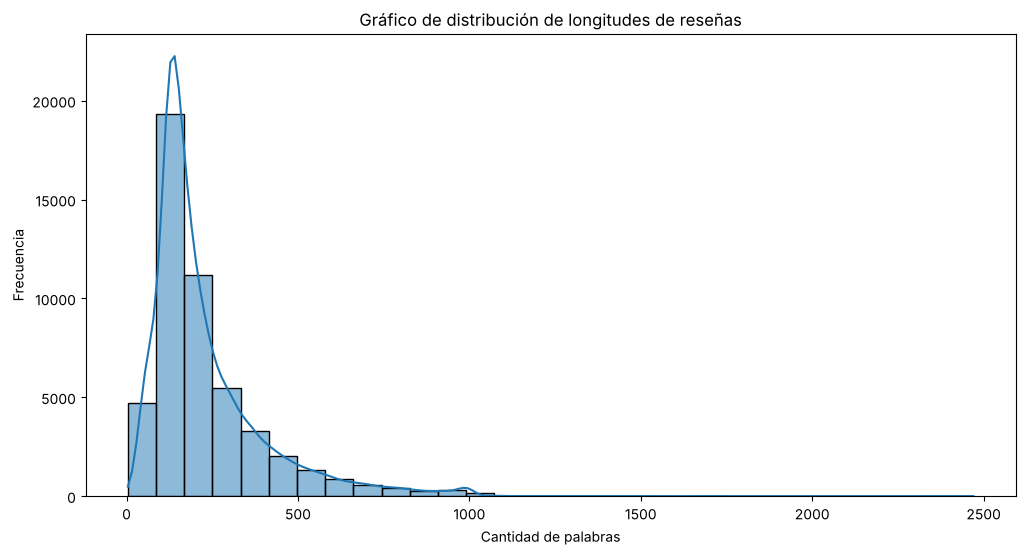

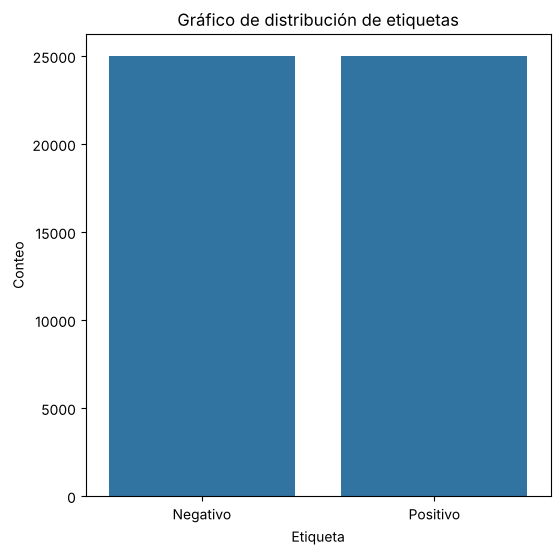

Promedio de longitud de reseñas positivas: 232.85 palabras
Promedio de longitud de reseñas negativas: 229.46 palabras


In [5]:
def word_count(text):
    return len(text.split())

review_lengths = [word_count(text) for text in texts]

# Plot the distribution of review lengths
plt.figure(figsize=(12, 6))
sns.histplot(review_lengths, bins=30, kde=True)
plt.title('Gráfico de distribución de longitudes de reseñas')
plt.xlabel('Cantidad de palabras')
plt.ylabel('Frecuencia')
plt.show()

# Plot the distribution of labels
label_counts = Counter(labels)
plt.figure(figsize=(6, 6))
sns.barplot(x=list(label_counts.keys()), y=list(label_counts.values()))
plt.title('Gráfico de distribución de etiquetas')
plt.xlabel('Etiqueta')
plt.ylabel('Conteo')
plt.xticks(ticks=[0, 1], labels=['Negativo', 'Positivo'])
plt.show()

average_positive_length = np.mean([review_lengths[i] for i in range(len(labels)) if labels[i] == 1])
average_negative_length = np.mean([review_lengths[i] for i in range(len(labels)) if labels[i] == 0])

print(f"Promedio de longitud de reseñas positivas: {average_positive_length:.2f} palabras")
print(f"Promedio de longitud de reseñas negativas: {average_negative_length:.2f} palabras")

### 3.- Estadísticas de longitud y formato del texto

Complementamos los gráficos con estadísticas descriptivas, la longitud por etiqueta y la proporción de reseñas
que superan los 128 elementos que usará el modelo.

Media: 231.2 palabras | Mediana: 173 | Desv. estándar: 171.3
Mínimo: 4 | Percentil 90: 451 | Máximo: 2470
Asimetría (skewness): 2.17  (> 0: cola larga hacia la derecha)
Reseñas con más de 128 palabras: 73.5%
Reseñas con saltos de línea HTML '<br />': 58.4%
Balance de etiquetas: Counter({0: 25000, 1: 25000})


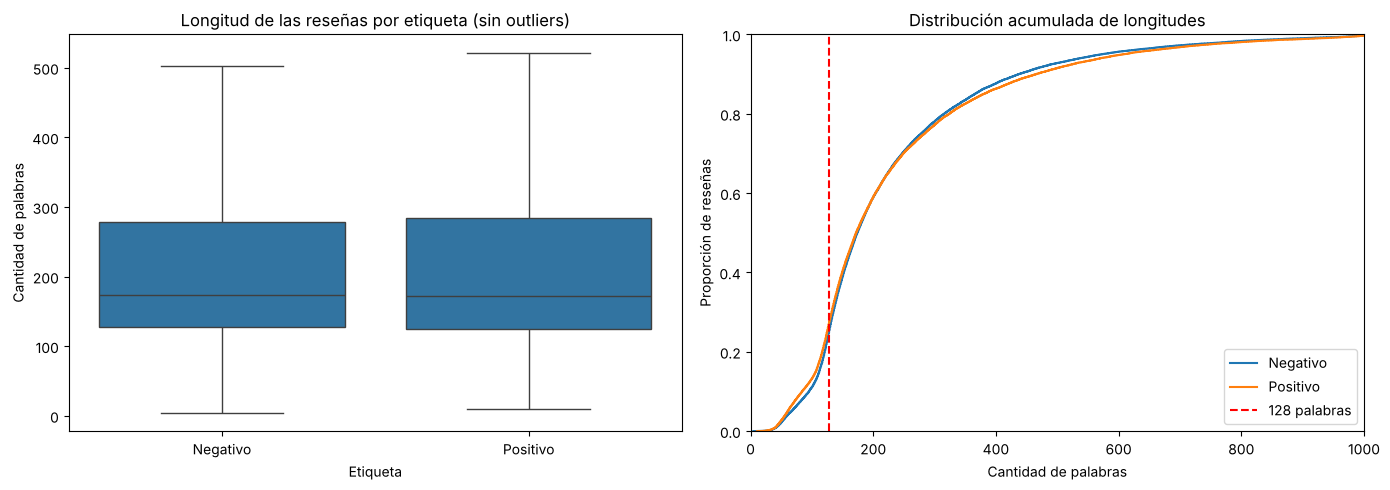

In [6]:
lengths = np.array(review_lengths)
labels_arr = np.array(labels)

print(f"Media: {lengths.mean():.1f} palabras | Mediana: {np.median(lengths):.0f} | Desv. estándar: {lengths.std():.1f}")
print(f"Mínimo: {lengths.min()} | Percentil 90: {np.percentile(lengths, 90):.0f} | Máximo: {lengths.max()}")
print(f"Asimetría (skewness): {pd.Series(lengths).skew():.2f}  (> 0: cola larga hacia la derecha)")
print(f"Reseñas con más de 128 palabras: {100 * (lengths > 128).mean():.1f}%")
print(f"Reseñas con saltos de línea HTML '<br />': {100 * np.mean(['<br' in t for t in texts]):.1f}%")
print(f"Balance de etiquetas: {Counter(labels)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=labels_arr, y=lengths, ax=axes[0], showfliers=False)
axes[0].set_xticks([0, 1], ['Negativo', 'Positivo'])
axes[0].set_title('Longitud de las reseñas por etiqueta (sin outliers)')
axes[0].set_xlabel('Etiqueta')
axes[0].set_ylabel('Cantidad de palabras')

for value, name in [(0, 'Negativo'), (1, 'Positivo')]:
    sns.ecdfplot(lengths[labels_arr == value], ax=axes[1], label=name)
axes[1].axvline(128, color='red', ls='--', label='128 palabras')
axes[1].set_xlim(0, 1000)
axes[1].set_title('Distribución acumulada de longitudes')
axes[1].set_xlabel('Cantidad de palabras')
axes[1].set_ylabel('Proporción de reseñas')
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación del EDA**

- La distribución de longitudes está **sesgada a la derecha** (asimetría 2,17): la mayoría de las reseñas son
  relativamente cortas (mediana 173 palabras), pero hay una cola larga de reseñas muy extensas (percentil 90 = 451,
  máximo 2.470). Por eso la media (231) es mayor que la mediana.
- Las etiquetas están **perfectamente balanceadas** (25.000 positivas y 25.000 negativas): la precisión es una
  métrica adecuada y el azar da 50%.
- La longitud casi no distingue el sentimiento: 232,9 palabras en promedio en las positivas y 229,5 en las
  negativas, y los boxplots y las curvas acumuladas prácticamente se superponen. El modelo tiene que basarse en el
  contenido, no en el largo.
- El 73,5% de las reseñas tiene más de 128 palabras: con `max_length = 128` el modelo verá solo el comienzo de la
  mayoría (más abajo se cuantifica en fragmentos BPE).
- El 58,4% contiene saltos de línea HTML `<br />`, que conviene limpiar antes de tokenizar.

## Tareas

### 1: Implementación del Tokenizador

- [x] Ampliar el tokenizador para que construya un vocabulario de 30.000 palabras y fragmentos de palabra (libro capítulo 12.5).
- [x] Mostrar el tamaño del vocabulario a lo largo de las iteraciones del algoritmo.

**Algoritmo (Byte Pair Encoding).** Se parte de un vocabulario con todos los caracteres más el marcador de fin de
palabra `_`. En cada iteración se cuentan los pares de símbolos adyacentes (ponderados por la frecuencia de la
palabra), se fusiona el par más frecuente y el nuevo fragmento se agrega al vocabulario, hasta llegar a 30.000.

Cambios respecto de la versión inicial:

- **Orden de las fusiones al codificar.** Antes se aplicaba el primer par fusionable de izquierda a derecha, por lo
  que `the` se codificaba como `the` + `_`. Ahora se aplican **en el mismo orden en que se aprendieron**
  (`merge_ranks`), como en BPE estándar, y `the` queda como un único fragmento `the_`.
- **Pre-tokenización.** Antes se separaba solo por espacios, así que `good`, `good.` y `good,` terminaban en
  fragmentos distintos (solo el primero produce `good_`) y los `<br />` del HTML se mezclaban con las palabras.
  Ahora se eliminan los `<br />` y la puntuación queda como token aparte. Con 800 reseñas cada palabra se ve
  pocas veces y no conviene repartir su señal entre varias variantes; en las pruebas preliminares, con la misma
  configuración, la precisión de validación subió de 75% a 79%.
- Se guarda el historial del tamaño del vocabulario para graficarlo, y un caché palabra → fragmentos.

In [7]:
import re
from collections import Counter, defaultdict

class SimpleTokenizer:
    def __init__(self, target_vocab_size=30000):
        self.target_vocab_size = target_vocab_size
        self.special_tokens = {'[PAD]': 0, '[UNK]': 1}
        self.vocab = {'[PAD]': 0, '[UNK]': 1}
        self.reverse_vocab = {0: '[PAD]', 1: '[UNK]'}
        self.merges = {}
        self.merge_ranks = {}  # par -> orden en que se aprendió la fusión
        self.history = []      # (iteración, tamaño del vocabulario, frecuencia del par fusionado)
        self.cache = {}        # palabra -> fragmentos ya calculados

    def tokenize(self, text):
        # Minúsculas, sin los saltos de línea HTML "<br />" y con la puntuación separada de las palabras,
        # para que "good", "good." y "good," compartan el mismo fragmento "good_".
        text = re.sub(r'<br\s*/?>', ' ', text.lower())
        return re.findall(r"\w+(?:'\w+)?|[^\w\s]", text)

    def _add_token(self, token):
        if token not in self.vocab:
            idx = len(self.vocab)
            self.vocab[token] = idx
            self.reverse_vocab[idx] = token

    def _init_char_vocab(self, texts):
        word_counts = Counter()
        for text in texts:
            word_counts.update(self.tokenize(text))

        splits = {word: list(word) + ['_'] for word in word_counts}
        for split in splits.values():
            for char in split:
                self._add_token(char)

        return word_counts, splits

    def _build_initial_stats(self, splits, word_counts):
        """Calcula las frecuencias de pares e índice invertido una sola vez."""
        pair_counts = Counter()
        pair_to_words = defaultdict(set)
        for word, freq in word_counts.items():
            symbols = splits[word]
            for i in range(len(symbols) - 1):
                pair = (symbols[i], symbols[i + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        return pair_counts, pair_to_words

    def _merge_pair_fast(self, best_pair, splits, word_counts, pair_counts, pair_to_words):
        """Fusiona el par ganador actualizando únicamente las palabras afectadas."""
        new_token = ''.join(best_pair)
        affected_words = list(pair_to_words.pop(best_pair, []))
        del pair_counts[best_pair]

        for word in affected_words:
            freq = word_counts[word]
            symbols = splits[word]
            if len(symbols) < 2:
                continue

            # 1. Restar conteos antiguos de esta palabra
            for i in range(len(symbols) - 1):
                old_p = (symbols[i], symbols[i + 1])
                if old_p != best_pair:
                    pair_counts[old_p] -= freq
                    if pair_counts[old_p] <= 0:
                        pair_counts.pop(old_p, None)

            # 2. Fusionar el par en la palabra
            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    new_symbols.append(new_token)
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            splits[word] = new_symbols

            # 3. Sumar los nuevos pares formados en esta palabra
            for i in range(len(new_symbols) - 1):
                new_p = (new_symbols[i], new_symbols[i + 1])
                pair_counts[new_p] += freq
                pair_to_words[new_p].add(word)

        return new_token

    def _apply_bpe_to_word(self, word):
        if word in self.cache:
            return self.cache[word]
        symbols = list(word) + ['_']
        # Aplicamos las fusiones en el mismo orden en que se aprendieron (menor rango primero)
        while len(symbols) >= 2:
            pairs = [(symbols[j], symbols[j + 1]) for j in range(len(symbols) - 1)]
            mergeable = [p for p in pairs if p in self.merge_ranks]
            if not mergeable:
                break
            best_pair = min(mergeable, key=self.merge_ranks.get)
            merged = self.merges[best_pair]
            new_symbols = []
            j = 0
            while j < len(symbols):
                if j < len(symbols) - 1 and (symbols[j], symbols[j + 1]) == best_pair:
                    new_symbols.append(merged)
                    j += 2
                else:
                    new_symbols.append(symbols[j])
                    j += 1
            symbols = new_symbols
        self.cache[word] = symbols
        return symbols

    def build_vocab(self, texts, sample_size=3000):
        sample_texts = texts[:sample_size] if sample_size else texts
        word_counts, splits = self._init_char_vocab(sample_texts)
        print(f"Vocabulario inicial (caracteres base): {self.vocab_size}")

        pair_counts, pair_to_words = self._build_initial_stats(splits, word_counts)

        iteration = 0
        self.history = [(iteration, self.vocab_size, None)]
        while self.vocab_size < self.target_vocab_size and pair_counts:
            best_pair, best_freq = pair_counts.most_common(1)[0]
            new_token = self._merge_pair_fast(
                best_pair, splits, word_counts, pair_counts, pair_to_words
            )

            self.merges[best_pair] = new_token
            self.merge_ranks[best_pair] = iteration
            self._add_token(new_token)
            iteration += 1
            self.history.append((iteration, self.vocab_size, best_freq))

            if iteration % 2500 == 0 or self.vocab_size == self.target_vocab_size:
                print(f"Iteración {iteration} -> Tamaño del vocabulario: {self.vocab_size}")
        self.cache = {}

    def count_subwords(self, text):
        """Cantidad de fragmentos del texto completo, antes de truncar o rellenar."""
        return sum(len(self._apply_bpe_to_word(word)) for word in self.tokenize(text))

    def encode(self, text, max_length=128):
        words = self.tokenize(text)
        subwords = []
        for word in words:
            subwords.extend(self._apply_bpe_to_word(word))

        token_ids = [self.vocab.get(token, self.vocab['[UNK]']) for token in subwords]

        if len(token_ids) < max_length:
            token_ids += [self.vocab['[PAD]']] * (max_length - len(token_ids))
        else:
            token_ids = token_ids[:max_length]
        return token_ids

    def decode(self, token_ids):
        tokens = [self.reverse_vocab.get(i, '[UNK]') for i in token_ids]
        return ''.join(tokens).replace('_', ' ').strip()

    @property
    def vocab_size(self):
        return len(self.vocab)

# --- INSTANCIAR Y EJECUTAR EL ENTRENAMIENTO DEL TOKENIZADOR ---
simple_tokenizer = SimpleTokenizer(target_vocab_size=30000)
simple_tokenizer.build_vocab(texts, sample_size=3000)

if simple_tokenizer.vocab_size < 29900 or simple_tokenizer.vocab_size > 30100:
    print(f"Vocabulary is incorrect: {simple_tokenizer.vocab_size}")
else:
    print(f"¡Vocabulario creado correctamente! Tamaño final: {simple_tokenizer.vocab_size}")

Vocabulario inicial (caracteres base): 102


Iteración 2500 -> Tamaño del vocabulario: 2602


Iteración 5000 -> Tamaño del vocabulario: 5102


Iteración 7500 -> Tamaño del vocabulario: 7602


Iteración 10000 -> Tamaño del vocabulario: 10102


...

Iteración 20000 -> Tamaño del vocabulario: 20102


Iteración 22500 -> Tamaño del vocabulario: 22602


Iteración 25000 -> Tamaño del vocabulario: 25102


Iteración 27500 -> Tamaño del vocabulario: 27602


Iteración 29898 -> Tamaño del vocabulario: 30000
¡Vocabulario creado correctamente! Tamaño final: 30000


### Tamaño del vocabulario a lo largo de las iteraciones

Cada iteración agrega exactamente un fragmento nuevo, por lo que el vocabulario crece linealmente desde los
caracteres base hasta 30.000. La frecuencia del par fusionado, en cambio, cae rápidamente: las primeras fusiones
forman terminaciones y palabras muy comunes (`e_`, `s_`, `th`, `the_`, `._`) y las últimas, palabras y fragmentos
que aparecen solo una o dos veces en las 3.000 reseñas.

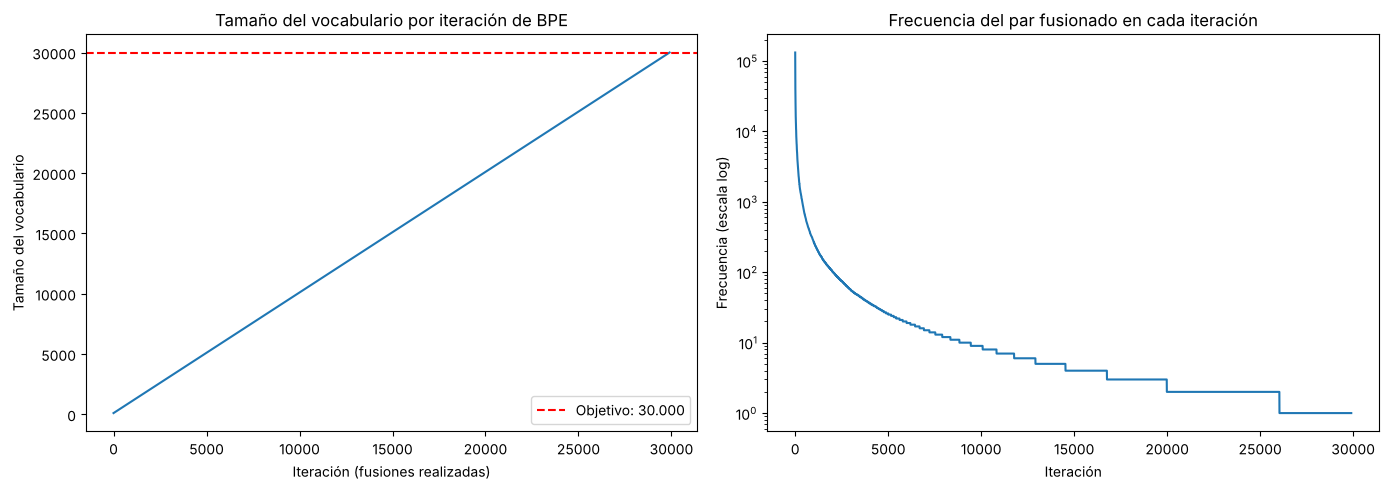

Iteración      0 -> vocabulario    102 | frecuencia del par fusionado: -
Iteración   1000 -> vocabulario   1102 | frecuencia del par fusionado: 266
Iteración   5000 -> vocabulario   5102 | frecuencia del par fusionado: 26
Iteración  10000 -> vocabulario  10102 | frecuencia del par fusionado: 9
Iteración  20000 -> vocabulario  20102 | frecuencia del par fusionado: 2
Iteración  29898 -> vocabulario  30000 | frecuencia del par fusionado: 1

Primeras 15 fusiones: ['e_', 's_', 'th', 't_', 'd_', 'in', 'er', 'y_', 'an', '._', 'the_', 'o_', ',_', 'on', 'en']
Últimas 15 fusiones:  ['telepathetic_', 'bathetic_', 'swimfan_', 'wimping_', 'wiser_', 'wispy_', 'wised_', 'lewi', 'jab_', 'jabber_', 'biscu', 'scum', 'rescuing_', 'label', 'tristra']


In [8]:
hist_iter, hist_vocab, hist_freq = zip(*simple_tokenizer.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hist_iter, hist_vocab)
axes[0].axhline(simple_tokenizer.target_vocab_size, color='red', ls='--', label='Objetivo: 30.000')
axes[0].set_title('Tamaño del vocabulario por iteración de BPE')
axes[0].set_xlabel('Iteración (fusiones realizadas)')
axes[0].set_ylabel('Tamaño del vocabulario')
axes[0].legend()

axes[1].plot(hist_iter[1:], hist_freq[1:])
axes[1].set_yscale('log')
axes[1].set_title('Frecuencia del par fusionado en cada iteración')
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('Frecuencia (escala log)')
plt.tight_layout()
plt.show()

for it in [0, 1000, 5000, 10000, 20000, len(hist_iter) - 1]:
    freq = hist_freq[it] if hist_freq[it] is not None else '-'
    print(f"Iteración {hist_iter[it]:>6} -> vocabulario {hist_vocab[it]:>6} | frecuencia del par fusionado: {freq}")

first_tokens = [simple_tokenizer.merges[p] for p in list(simple_tokenizer.merges)[:15]]
last_tokens = [simple_tokenizer.merges[p] for p in list(simple_tokenizer.merges)[-15:]]
print(f"\nPrimeras 15 fusiones: {first_tokens}")
print(f"Últimas 15 fusiones:  {last_tokens}")

### Prueba del Tokenizador

Verificaremos que el tokenizador funciona correctamente codificando y decodificando un texto de ejemplo.

In [9]:
print("Ejemplo de codificación:")
print(simple_tokenizer.encode("The movie was maravilloso"))
print("\nEjemplo de decodificación:")
print(simple_tokenizer.decode(simple_tokenizer.encode("The movie was maravilloso")))
print("\nFragmentos:")
print([simple_tokenizer.reverse_vocab[i] for i in simple_tokenizer.encode("The movie was maravilloso") if i != 0])

Ejemplo de codificación:
[112, 188, 184, 493, 769, 136, 334, 229, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Ejemplo de decodificación:
the movie was maravilloso [PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD]

In [10]:
print(f"Imprimir 15 de la totalidad del vocabulario de tamaño {simple_tokenizer.vocab_size}")
for idx, key in enumerate(simple_tokenizer.vocab):
    print(f"palabra o fragmento correspondiente '{key}' con su token {simple_tokenizer.vocab[key]}")
    if idx == 15:
        break

Imprimir 15 de la totalidad del vocabulario de tamaño 30000
palabra o fragmento correspondiente '[PAD]' con su token 0
palabra o fragmento correspondiente '[UNK]' con su token 1
palabra o fragmento correspondiente 'i' con su token 2
palabra o fragmento correspondiente '_' con su token 3
palabra o fragmento correspondiente 'r' con su token 4
palabra o fragmento correspondiente 'e' con su token 5
palabra o fragmento correspondiente 'n' con su token 6
palabra o fragmento correspondiente 't' con su token 7
palabra o fragmento correspondiente 'd' con su token 8
palabra o fragmento correspondiente 'a' con su token 9
palabra o fragmento correspondiente 'm' con su token 10
palabra o fragmento correspondiente 'c' con su token 11
palabra o fragmento correspondiente 'u' con su token 12
palabra o fragmento correspondiente 'o' con su token 13
palabra o fragmento correspondiente 's' con su token 14
palabra o fragmento correspondiente '-' con su token 15


## Preparación del Conjunto de Datos

Este conjunto de datos se ha reducido a 1500 desde 50.000 para que puedas desarrollar en una instancia de **Google Colab con GPU**. Con la GPU activada, el entrenamiento será mucho más rápido. Si usas CPU, también será posible pero tomará más tiempo.

Crearemos los conjuntos de entrenamiento, validación y prueba.

In [11]:
# Implementación del conjunto de datos IMDB
class IMDBDataset(Dataset):
    def __init__(self, tokenizer, max_length=128, seed=42):
        dataset = load_dataset('stanfordnlp/imdb')
        texts = list(dataset['train']['text']) + list(dataset['test']['text'])
        labels = list(dataset['train']['label']) + list(dataset['test']['label'])
        data = list(zip(texts, labels))
        random.Random(seed).shuffle(data)
        self.texts, self.labels = zip(*data)
        self.texts = self.texts[:1500]
        self.labels = self.labels[:1500]
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        inputs = self.tokenizer.encode(text, max_length=self.max_length)
        return torch.tensor(inputs, dtype=torch.long), label

# longitud de secuencia
max_length = 128
dataset = IMDBDataset(simple_tokenizer, max_length=max_length)

# Dividir el conjunto de datos en conjuntos de entrenamiento, validación y prueba
train_size = 800
val_size = 200
test_size = 500
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(random_seed))

# DataLoader para batchear
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

print(f"Tamaños de los conjuntos - Entrenamiento: {len(train_dataset)}, Validación: {len(val_dataset)}, Prueba: {len(test_dataset)}")

Tamaños de los conjuntos - Entrenamiento: 800, Validación: 200, Prueba: 500


### Balance de etiquetas y truncamiento del subconjunto

Revisamos que las tres particiones estén balanceadas y cuántas reseñas quedan truncadas con `max_length = 128`
fragmentos (la reseña se corta y el modelo no ve el resto).

Entrenamiento:  800 reseñas | positivas: 47.8%
Validación   :  200 reseñas | positivas: 46.5%
Prueba       :  500 reseñas | positivas: 50.8%



Fragmentos BPE por palabra: 1.21
Fragmentos por reseña -> media: 278, mediana: 210
Reseñas truncadas con max_length=128: 85.0%
Reseñas truncadas con max_length=256: 38.2%
Reseñas truncadas con max_length=512: 10.9%


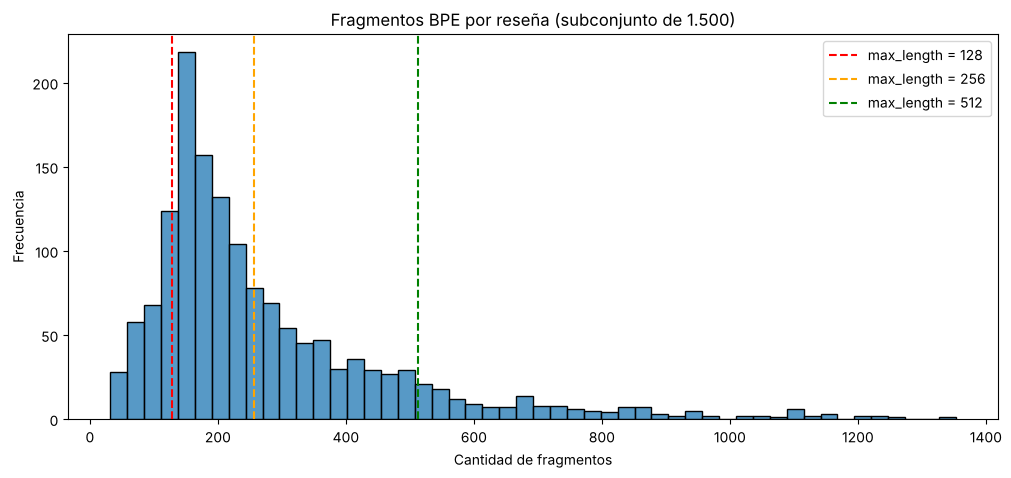

In [12]:
for name, subset in [('Entrenamiento', train_dataset), ('Validación', val_dataset), ('Prueba', test_dataset)]:
    y = np.array([dataset.labels[i] for i in subset.indices])
    print(f"{name:13s}: {len(y):4d} reseñas | positivas: {100 * y.mean():.1f}%")

subset_words = np.array([word_count(t) for t in dataset.texts])
subset_tokens = np.array([simple_tokenizer.count_subwords(t) for t in dataset.texts])
print(f"\nFragmentos BPE por palabra: {subset_tokens.sum() / subset_words.sum():.2f}")
print(f"Fragmentos por reseña -> media: {subset_tokens.mean():.0f}, mediana: {np.median(subset_tokens):.0f}")
for L in [128, 256, 512]:
    print(f"Reseñas truncadas con max_length={L}: {100 * (subset_tokens > L).mean():.1f}%")

plt.figure(figsize=(12, 5))
sns.histplot(subset_tokens, bins=50)
for L, color in [(128, 'red'), (256, 'orange'), (512, 'green')]:
    plt.axvline(L, color=color, ls='--', label=f'max_length = {L}')
plt.title('Fragmentos BPE por reseña (subconjunto de 1.500)')
plt.xlabel('Cantidad de fragmentos')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

## Modelo

### 2: Mecanismo de Atención

- [x] Capa de atención unidireccional **SingleHeadAttention** con matrices de Query, Key y Value $Q_q, Q_k, Q_v$ (libro capítulo 12.2)
- [x] **Ajustado** Punto de dot producto de escala (libro capítulo 12.3.2)

Siguiendo el libro (con los tokens como filas de $X \in \mathbb{R}^{N \times D}$):

$$Q = X\Omega_q^T + \beta_q, \quad K = X\Omega_k^T + \beta_k, \quad V = X\Omega_v^T + \beta_v, \qquad
\mathrm{Sa}[X] = \mathrm{Softmax}\left[\frac{QK^T}{\sqrt{D_q}}\right] V$$

El softmax se aplica por fila: cada token reparte una unidad de "atención" entre todos los tokens. Dividir por
$\sqrt{D_q}$ evita que los productos punto crezcan con la dimensión y saturen el softmax (gradientes casi nulos).
Se agrega una **máscara de padding** opcional para que ningún token atienda a `[PAD]`. Al final de la celda se
incluye `MultiHeadAttention` (cap. 12.3.3), que se usa en los modelos más grandes y en el bonus.

In [13]:
class ScaledDotProductAttention(nn.Module):
    """
    Implementación de la atención unidireccional escalada por punto de escala,
    utilizada en las transformadoras.

    - Utiliza la función dot producto escalada para calcular los pesos de atención.
    - Aplica la función softmax para obtener las probabilidades de atención.
    - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output.
    """
    def __init__(self, dim_model):
        super(ScaledDotProductAttention, self).__init__()
        # Factor de escala sqrt(D_q) del libro (cap. 12.3.2)
        self.scale = math.sqrt(dim_model)

    def forward(self, query, key, value, mask=None):
        """
        Procesar los inputs y obtener el output.

        - Calcula las matrices de dot producto entre query y key.
        - Divide las matrices de dot producto por la escala.
        - Aplica la función softmax para obtener las probabilidades de atención.
        - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output.

        Parámetros:
            query, key, value (tensor): (..., N, D)
            mask (tensor bool, opcional): True en las posiciones que se pueden atender,
                con forma que se pueda transmitir (broadcast) a (..., N, N).

        Returns:
            output (tensor): El output de la capa de atención.
            attn_weights (tensor): Las probabilidades de atención.
        """
        scores = torch.matmul(query, key.transpose(-2, -1)) / self.scale
        if mask is not None:
            # Valor muy negativo (no -inf) para no generar NaN si una fila queda sin tokens válidos
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        attn_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attn_weights, value)
        return output, attn_weights

class SingleHeadAttention(nn.Module):
    """
    Implementación de la atención unidireccional con varias capas lineales,
    utilizada en las transformadoras.

    - Utiliza varias capas lineales para calcular las matrices de query, key y value.
    - Aplica la capa de atención escalada por punto de escala para obtener las probabilidades de atención.
    - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output final.
    """
    def __init__(self, dim_model):
        super(SingleHeadAttention, self).__init__()
        # Matrices Omega_q, Omega_k, Omega_v (con sus sesgos beta) del libro
        self.W_q = nn.Linear(dim_model, dim_model)
        self.W_k = nn.Linear(dim_model, dim_model)
        self.W_v = nn.Linear(dim_model, dim_model)
        self.attention = ScaledDotProductAttention(dim_model)
        self.attn_weights = None  # últimos pesos de atención, para inspección

    def forward(self, x, mask=None):
        """
        Procesar los inputs y obtener el output.

        - Calcula las matrices de query, key y value utilizando varias capas lineales.
        - Aplica la capa de atención escalada por punto de escala para obtener las probabilidades de atención.
        - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output final.

        Parámetros:
            x (tensor): (batch, N, dim_model)
            mask (tensor bool, opcional): (batch, N), True en los tokens reales y False en [PAD].

        Returns:
            output (tensor): El output final de la capa de atención.
        """
        query, key, value = self.W_q(x), self.W_k(x), self.W_v(x)
        if mask is not None:
            mask = mask[:, None, :]  # (batch, 1, N): la misma máscara de keys para cada query
        output, attn_weights = self.attention(query, key, value, mask)
        self.attn_weights = attn_weights.detach()
        return output

class MultiHeadAttention(nn.Module):
    """
    Atención multi-cabeza (libro cap. 12.3.3): H cabezas de dimensión D/H calculadas en paralelo,
    concatenadas y combinadas con una proyección de salida Omega_c.
    """
    def __init__(self, dim_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert dim_model % num_heads == 0, "dim_model debe ser divisible por num_heads"
        self.num_heads = num_heads
        self.dim_head = dim_model // num_heads
        self.W_q = nn.Linear(dim_model, dim_model)
        self.W_k = nn.Linear(dim_model, dim_model)
        self.W_v = nn.Linear(dim_model, dim_model)
        self.W_o = nn.Linear(dim_model, dim_model)
        self.attention = ScaledDotProductAttention(self.dim_head)
        self.attn_weights = None

    def _split_heads(self, t):
        batch_size, seq_len, _ = t.shape
        return t.view(batch_size, seq_len, self.num_heads, self.dim_head).transpose(1, 2)

    def forward(self, x, mask=None):
        batch_size, seq_len, dim_model = x.shape
        query = self._split_heads(self.W_q(x))  # (batch, H, N, D/H)
        key = self._split_heads(self.W_k(x))
        value = self._split_heads(self.W_v(x))
        if mask is not None:
            mask = mask[:, None, None, :]  # (batch, 1, 1, N)
        output, attn_weights = self.attention(query, key, value, mask)
        self.attn_weights = attn_weights.detach()
        output = output.transpose(1, 2).reshape(batch_size, seq_len, dim_model)
        return self.W_o(output)

In [14]:
# Verificación de la atención contra la implementación de PyTorch
torch.manual_seed(0)
q, k, v = torch.randn(3, 2, 5, 16).unbind(0)
pad_mask = torch.tensor([[True] * 5, [True] * 3 + [False] * 2])  # la 2.ª secuencia tiene 2 [PAD]

out, w = ScaledDotProductAttention(16)(q, k, v, pad_mask[:, None, :])
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=pad_mask[:, None, :])
print("Los pesos de cada fila suman 1:", torch.allclose(w.sum(dim=-1), torch.ones(2, 5)))
print("Peso máximo asignado a [PAD]:", w[1, :, 3:].max().item())
print("Igual a F.scaled_dot_product_attention:", torch.allclose(out, ref, atol=1e-6))

x = torch.randn(8, max_length, 32)
print("Salida SingleHeadAttention:", SingleHeadAttention(32)(x).shape)
print("Salida MultiHeadAttention (4 cabezas):", MultiHeadAttention(32, 4)(x).shape)
_ = torch.manual_seed(random_seed)

Los pesos de cada fila suman 1: True
Peso máximo asignado a [PAD]: 0.0
Igual a F.scaled_dot_product_attention: True
Salida SingleHeadAttention: torch.Size([8, 128, 32])
Salida MultiHeadAttention (4 cabezas): torch.Size([8, 128, 32])


### 3: Capa del Transformer

- [x] Unir los elementos de la capa SingleHeadAttention, Block de normalización por capa (nn.LayerNorm) y el bloque de forward feedforward (nn.Linear) con una capa de normalización final (libro capítulo 12.4)
- [x] No olvidar las conexiones residuales

En general, se recomienda utilizar ReLU y además técnicas de regularización para mejorar la generalización del modelo a los datos de prueba (como Dropout).

Se implementa la versión del libro (post-LN), donde cada subcapa suma su salida a la entrada (conexión residual)
y luego normaliza:

1. $X \leftarrow \mathrm{LayerNorm}\left[X + \mathrm{Dropout}(\mathrm{Sa}[X])\right]$
2. $X \leftarrow \mathrm{LayerNorm}\left[X + \mathrm{Dropout}(\mathrm{FFN}[X])\right]$, con
   $\mathrm{FFN} = \mathrm{Linear}(D \to D_{ff}) \to \mathrm{ReLU} \to \mathrm{Dropout} \to \mathrm{Linear}(D_{ff} \to D)$
   aplicado a cada token por separado; la segunda `LayerNorm` es la normalización final de la capa.

Con `num_heads = 1` usa `SingleHeadAttention`; con más cabezas, `MultiHeadAttention`.

In [15]:
class TransformerEncoderLayer(nn.Module):
    """
    Una capa única en la arquitectura del codificador de transformer.

    Esta clase define un paso adelante que aplica atención autoregresa, seguido de dos capas lineales y normalización de capa.
    """
    def __init__(self, dim_model, dim_feedforward, num_heads=1, dropout=0.1):
        super(TransformerEncoderLayer, self).__init__()
        if num_heads == 1:
            self.self_attn = SingleHeadAttention(dim_model)
        else:
            self.self_attn = MultiHeadAttention(dim_model, num_heads)
        self.norm1 = nn.LayerNorm(dim_model)
        self.feedforward = nn.Sequential(
            nn.Linear(dim_model, dim_feedforward),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, dim_model),
        )
        self.norm2 = nn.LayerNorm(dim_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, src, mask=None):
        """
        Paso adelante a través de la capa del codificador de transformer.

        Parámetros:
            src (Tensor): Tensor de entrada a ser procesado por la capa, torch.Size([8, 128, 32])
            mask (Tensor bool, opcional): (batch, N), True en los tokens reales y False en [PAD].

        Regresa:
            Tensor: Tensor de salida después de aplicar la atención autoregresa y el FFN.
        """
        # 1) Auto-atención + conexión residual + LayerNorm
        src = self.norm1(src + self.dropout1(self.self_attn(src, mask)))
        # 2) Feed-forward por token + conexión residual + LayerNorm final
        src = self.norm2(src + self.dropout2(self.feedforward(src)))
        return src

### Arquitectura del Modelo

El **SentimentAnalysisModel** básico se proporciona. Este modelo combina todos los componentes anteriores para crear un clasificador de sentimientos.

In [16]:
class SentimentAnalysisModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super(SentimentAnalysisModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.encoder = TransformerEncoderLayer(embed_dim, hidden_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, src):
        src = self.embedding(src)
        encoded_output = self.encoder(src)
        pooled_output = encoded_output.mean(dim=1)
        return self.fc(pooled_output)

# Puedes experimentar con diferentes parámetros hiperbásicos, como la embedding o el dimensión oculta.
# Tal como puedes ajustar los parámetros de aprendizaje para mejorar el rendimiento del modelo.
embed_dim = 32
hidden_dim = 128
num_classes = 2
vocab_size = simple_tokenizer.vocab_size
model = SentimentAnalysisModel(vocab_size, embed_dim, hidden_dim, num_classes)

# Test with synthetic data
fake_data = torch.randint(0, vocab_size, (8, max_length))
fake_output = model(fake_data)
assert fake_output.shape == (8, num_classes), "Output shape is incorrect"
print(f"Modelo creado exitosamente. Shape de salida: {fake_output.shape}")
model

Modelo creado exitosamente. Shape de salida: torch.Size([8, 2])


SentimentAnalysisModel(
  (embedding): Embedding(30000, 32)
  (encoder): TransformerEncoderLayer(
    (self_attn): SingleHeadAttention(
      (W_q): Linear(in_features=32, out_features=32, bias=True)
      (W_k): Linear(in_features=32, out_features=32, bias=True)
      (W_v): Linear(in_features=32, out_features=32, bias=True)
      (attention): ScaledDotProductAttention()
    )
    (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (feedforward): Sequential(
      (0): Linear(in_features=32, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=32, bias=True)
    )
    (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout1): Dropout(p=0.1, inplace=False)
    (dropout2): Dropout(p=0.1, inplace=False)
  )
  (fc): Linear(in_features=32, out_features=2, bias=True)
)

### Modelo mejorado: varias capas y cabezas, posición y máscara de padding

El modelo provisto tiene tres limitaciones: (1) no recibe información de posición, (2) los tokens atienden a los
`[PAD]` y (3) el promedio final incluye los `[PAD]`, por lo que una reseña corta queda "diluida". `TransformerClassifier`
agrega una **codificación posicional sinusoidal** (cap. 12.3.1), una **máscara de padding** en la atención y en el
promedio, y permite apilar `num_layers` capas con `num_heads` cabezas. Se usa para comparar tamaños y para el bonus.

Dos detalles de escala, ajustados en pruebas preliminares (por precisión de validación):

- Los embeddings se inicializan con desviación 0,1 en vez de 1 (valor por defecto de PyTorch): las palabras poco
  vistas quedan cerca de cero en vez de meter ruido grande al promedio final. En las pruebas preliminares, las
  configuraciones con esta inicialización llegaron a 78–79% en validación, contra 74–75% sin ella (aunque esas
  pruebas también variaban otros hiperparámetros).
- La codificación sinusoidal (valores entre −1 y 1) se multiplica por esa misma escala 0,1. Sin este ajuste la
  posición pesaba ~10 veces más que la palabra al inicio, y los modelos con 128 o más dimensiones pasaban varias
  épocas cerca del 50% antes de empezar a aprender (el early stopping los cortaba ahí).

In [17]:
def sinusoidal_encoding(max_length, dim):
    """Codificación posicional fija con senos y cosenos de distintas frecuencias."""
    position = torch.arange(max_length).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, dim, 2) * (-math.log(10000.0) / dim))
    encoding = torch.zeros(max_length, dim)
    encoding[:, 0::2] = torch.sin(position * div_term)
    encoding[:, 1::2] = torch.cos(position * div_term)
    return encoding


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, num_heads=1, max_length=512, dropout=0.1, embed_init_std=0.1):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # Inicialización pequeña (por defecto PyTorch usa N(0, 1)): con pocos datos, los embeddings de palabras
        # poco vistas quedan cerca de cero en vez de aportar ruido grande al promedio final
        nn.init.normal_(self.embedding.weight, std=embed_init_std)
        with torch.no_grad():
            self.embedding.weight[0].zero_()
        # Posición sinusoidal escalada a la misma magnitud que los embeddings, para no tapar la identidad del token
        self.register_buffer('positional_encoding', embed_init_std * sinusoidal_encoding(max_length, embed_dim))
        self.dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            TransformerEncoderLayer(embed_dim, hidden_dim, num_heads=num_heads, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, src):
        mask = src != 0  # True en tokens reales, False en [PAD]
        x = self.dropout(self.embedding(src) + self.positional_encoding[:src.size(1)])
        for layer in self.layers:
            x = layer(x, mask)
        # Promedio solo sobre los tokens reales
        mask_f = mask.unsqueeze(-1).float()
        pooled = (x * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1)
        return self.fc(self.dropout(pooled))


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    embedding = model.embedding.weight.numel()
    return total, total - embedding


test_model = TransformerClassifier(vocab_size, 64, 256, num_classes, num_layers=2, num_heads=4)
assert test_model(fake_data).shape == (8, num_classes), "Output shape is incorrect"
print(f"TransformerClassifier OK. Shape de salida: {test_model(fake_data).shape}")
total, sin_embedding = count_parameters(model)
print(f"Parámetros del modelo base: {total:,} (sin la tabla de embeddings: {sin_embedding:,})")
del test_model

TransformerClassifier OK. Shape de salida: torch.Size([8, 2])
Parámetros del modelo base: 971,714 (sin la tabla de embeddings: 11,714)


## Fase de Entrenamiento

### 4: Entrenamiento

- [x] Implementar el mecanismo de detección temprana o otra monitoreo del progreso de aprendizaje
- [x] Experimentar con tamaños más grandes de modelos y comparar el rendimiento obtenido con la cantidad de parámetros requeridos

**Monitoreo y early stopping.** `train_model` registra en cada época la pérdida y la precisión de entrenamiento y
validación, guarda una copia de los pesos cada vez que mejora la **precisión de validación** (en empate, la de
menor pérdida) y se detiene si no mejora durante `patience` épocas seguidas; al final restaura los pesos de la
mejor época. Se monitorea la precisión y no la pérdida porque, con tan pocos datos, la pérdida de validación
empieza a subir muy temprano (el modelo se vuelve demasiado confiado en los ejemplos que falla) mientras la
precisión todavía mejora: con la pérdida como criterio se restauraban épocas con ~55–60% de precisión. Además se usa AdamW (con
*weight decay*), recorte de gradiente y *warm-up* lineal de la tasa de aprendizaje en la primera época (sin él, el
modelo más grande, de 4 capas, quedaba atascado prediciendo siempre la misma clase). El modelo, los textos y las etiquetas se mueven a `device` (GPU si está
disponible), y las variables del loop se llaman `batch_texts` / `batch_labels` para no sobrescribir `texts` y
`labels` del EDA.

Epoch:  1 | Training Loss: 0.7025, Training Acc: 49.75% | Validation Loss: 0.6930, Validation Accuracy: 51.00%  <- mejor


Epoch:  2 | Training Loss: 0.7047, Training Acc: 47.12% | Validation Loss: 0.6882, Validation Accuracy: 54.50%  <- mejor


Epoch:  3 | Training Loss: 0.6805, Training Acc: 57.88% | Validation Loss: 0.6824, Validation Accuracy: 56.00%  <- mejor


Epoch:  4 | Training Loss: 0.6336, Training Acc: 66.88% | Validation Loss: 0.6964, Validation Accuracy: 53.50%


Epoch:  5 | Training Loss: 0.5116, Training Acc: 75.25% | Validation Loss: 0.7569, Validation Accuracy: 58.00%  <- mejor


...

Epoch: 14 | Training Loss: 0.0016, Training Acc: 100.00% | Validation Loss: 1.6929, Validation Accuracy: 65.50%


Epoch: 15 | Training Loss: 0.0012, Training Acc: 100.00% | Validation Loss: 1.7296, Validation Accuracy: 65.00%


Epoch: 16 | Training Loss: 0.0009, Training Acc: 100.00% | Validation Loss: 1.7667, Validation Accuracy: 65.00%


Epoch: 17 | Training Loss: 0.0008, Training Acc: 100.00% | Validation Loss: 1.7955, Validation Accuracy: 65.00%


Epoch: 18 | Training Loss: 0.0006, Training Acc: 100.00% | Validation Loss: 1.8279, Validation Accuracy: 65.00%
Early stopping en la época 18: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 11: Validation Loss 1.5174, Validation Accuracy 66.50%


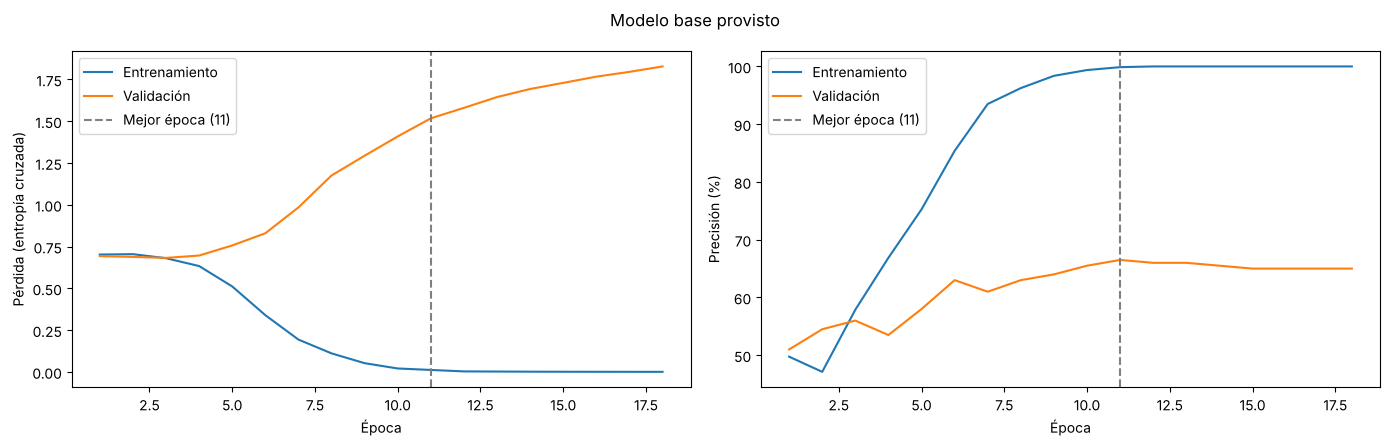

In [18]:
criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    """Devuelve (pérdida promedio, precisión %) del modelo sobre un DataLoader."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for batch_texts, batch_labels in loader:
            batch_texts, batch_labels = batch_texts.to(device), batch_labels.to(device)
            outputs = model(batch_texts)
            total_loss += criterion(outputs, batch_labels).item() * batch_labels.size(0)
            correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
            total += batch_labels.size(0)
    return total_loss / total, 100 * correct / total


def train_model(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=0.01, patience=7,
                warmup_epochs=1, verbose=True):
    """Entrena con AdamW y early stopping sobre la precisión de validación (empates: menor pérdida).

    La tasa de aprendizaje sube linealmente desde ~0 hasta `lr` durante las primeras `warmup_epochs` épocas.
    Al terminar restaura los pesos de la mejor época y devuelve el historial de métricas.
    """
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    warmup_steps = max(1, warmup_epochs * len(train_loader))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min(1.0, (step + 1) / warmup_steps))
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_score, best_epoch, best_state, bad_epochs = (-1.0, 0.0), 0, None, 0

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for batch_texts, batch_labels in train_loader:
            batch_texts, batch_labels = batch_texts.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            output = model(batch_texts)
            loss = criterion(output, batch_labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item() * batch_labels.size(0)
            correct += (output.argmax(dim=1) == batch_labels).sum().item()
            total += batch_labels.size(0)

        val_loss, val_acc = evaluate(model, val_loader)
        for key, value in zip(history, (total_loss / total, 100 * correct / total, val_loss, val_acc)):
            history[key].append(value)

        score = (val_acc, -val_loss)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad_epochs = score, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
        if verbose:
            print(f"Epoch: {epoch+1:2d} | Training Loss: {history['train_loss'][-1]:.4f}, "
                  f"Training Acc: {history['train_acc'][-1]:.2f}% | "
                  f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.2f}%"
                  + ("  <- mejor" if improved else ""))
        if bad_epochs >= patience:
            print(f"Early stopping en la época {epoch+1}: la precisión de validación no mejora hace {patience} épocas.")
            break

    model.load_state_dict(best_state)
    history['best_epoch'] = best_epoch
    print(f"Se restauran los pesos de la época {best_epoch}: Validation Loss {history['val_loss'][best_epoch - 1]:.4f}, "
          f"Validation Accuracy {history['val_acc'][best_epoch - 1]:.2f}%")
    return history


def plot_history(history, title):
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs_range, history['train_loss'], label='Entrenamiento')
    axes[0].plot(epochs_range, history['val_loss'], label='Validación')
    axes[0].set_ylabel('Pérdida (entropía cruzada)')
    axes[1].plot(epochs_range, history['train_acc'], label='Entrenamiento')
    axes[1].plot(epochs_range, history['val_acc'], label='Validación')
    axes[1].set_ylabel('Precisión (%)')
    for ax in axes:
        ax.axvline(history['best_epoch'], color='gray', ls='--', label=f"Mejor época ({history['best_epoch']})")
        ax.set_xlabel('Época')
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Modelo base provisto (embed_dim=32, hidden_dim=128, 1 capa, 1 cabeza)
history_base = train_model(model, train_loader, val_loader, epochs=40, lr=1e-3)
plot_history(history_base, 'Modelo base provisto')

**Modelo base.** La precisión de entrenamiento llega a 100% en la época 12, mientras la de validación se estanca
en torno a 65–66%: con 800 reseñas y ~970 mil parámetros (casi todos en la tabla de embeddings) el modelo memoriza
el entrenamiento. Las curvas también muestran por qué se monitorea la precisión: la pérdida de validación es
mínima en la época 3 (0,682, con solo 56% de precisión) y después sube sin parar, aunque la precisión siga
mejorando hasta 66,5% en la época 11. El early stopping detuvo el entrenamiento en la época 18 y restauró la 11.

### Comparación de tamaños de modelo

Se entrenan, con el mismo protocolo (semilla, datos, `max_length = 128`, batch de 16, dropout 0,3, *weight decay*
0,1 y early stopping), `TransformerClassifier` de tamaño creciente: más dimensiones de embedding, capas y cabezas.
Se reporta el total de parámetros y los parámetros **sin** la tabla de embeddings (que con 30.000 fragmentos
domina el total). El mejor modelo se elige por **precisión de validación**; la columna de prueba es solo
informativa.

In [19]:
size_configs = [
    # nombre, embed_dim, hidden_dim, num_layers, num_heads, lr
    ('XS', 32, 128, 1, 1, 1e-3),
    ('S', 64, 256, 2, 4, 1e-3),
    ('M', 128, 512, 2, 4, 1e-3),
    ('L', 256, 1024, 4, 8, 5e-4),
]
train_loader_16 = DataLoader(train_dataset, batch_size=16, shuffle=True)


def summarize(name, model, history, seconds, max_len, layers, heads, embed):
    total, sin_embedding = count_parameters(model)
    _, test_acc = evaluate(model, test_eval_loader if max_len == max_length else test_eval_loader_long)
    return {'modelo': name, 'max_length': max_len, 'embed_dim': embed, 'capas': layers, 'cabezas': heads,
            'parámetros': total, 'parámetros sin embedding': sin_embedding,
            'mejor época': history['best_epoch'], 'val_acc': history['val_acc'][history['best_epoch'] - 1],
            'test_acc': test_acc, 'tiempo (s)': round(seconds, 1)}


test_eval_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
trained_models = {'Base (provisto)': model}
results = [summarize('Base (provisto)', model, history_base, float('nan'), max_length, 1, 1, embed_dim)]
histories = {'Base (provisto)': history_base}

for name, emb, hid, layers, heads, lr in size_configs:
    torch.manual_seed(random_seed)
    candidate = TransformerClassifier(vocab_size, emb, hid, num_classes, num_layers=layers,
                                      num_heads=heads, max_length=max_length, dropout=0.3)
    print(f"\n=== Modelo {name}: embed {emb}, FFN {hid}, {layers} capa(s), {heads} cabeza(s) ===")
    start = time.time()
    histories[name] = train_model(candidate, train_loader_16, val_loader, epochs=40, lr=lr, weight_decay=0.1,
                                  verbose=False)
    trained_models[name] = candidate
    results.append(summarize(name, candidate, histories[name], time.time() - start, max_length, layers, heads, emb))

results_df = pd.DataFrame(results).set_index('modelo')
results_df


=== Modelo XS: embed 32, FFN 128, 1 capa(s), 1 cabeza(s) ===


Early stopping en la época 13: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 6: Validation Loss 0.6484, Validation Accuracy 74.00%

=== Modelo S: embed 64, FFN 256, 2 capa(s), 4 cabeza(s) ===


Early stopping en la época 11: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 4: Validation Loss 0.7873, Validation Accuracy 71.00%



=== Modelo M: embed 128, FFN 512, 2 capa(s), 4 cabeza(s) ===


Early stopping en la época 15: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 8: Validation Loss 1.6966, Validation Accuracy 75.00%



=== Modelo L: embed 256, FFN 1024, 4 capa(s), 8 cabeza(s) ===


Early stopping en la época 19: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 12: Validation Loss 1.9648, Validation Accuracy 75.50%


,max_length,embed_dim,capas,cabezas,parámetros,parámetros sin embedding,mejor época,val_acc,test_acc,tiempo (s)
modelo,,,,,,,,,,
Base (provisto),128,32,1,1,971714,11714,11,66.5,65.6,NaN
XS,128,32,1,1,971714,11714,6,74.0,70.6,10.9
S,128,64,2,4,2020098,100098,4,71.0,69.4,26.8
M,128,128,2,4,4236802,396802,8,75.0,73.2,64.9
L,128,256,4,8,10839554,3159554,12,75.5,71.2,300.3


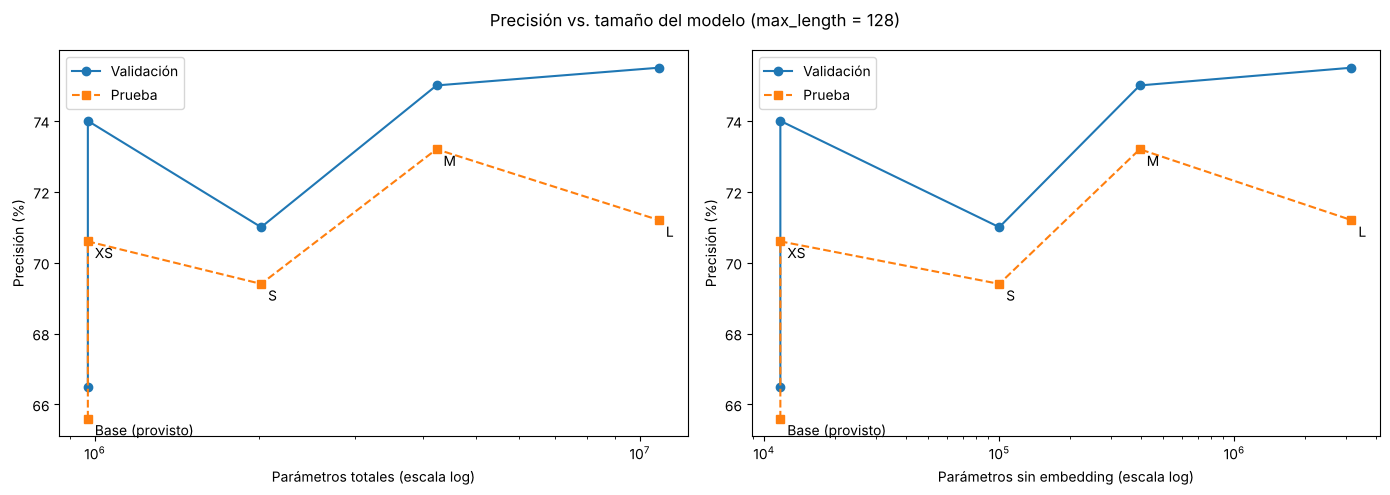

Mejor modelo por validación: L


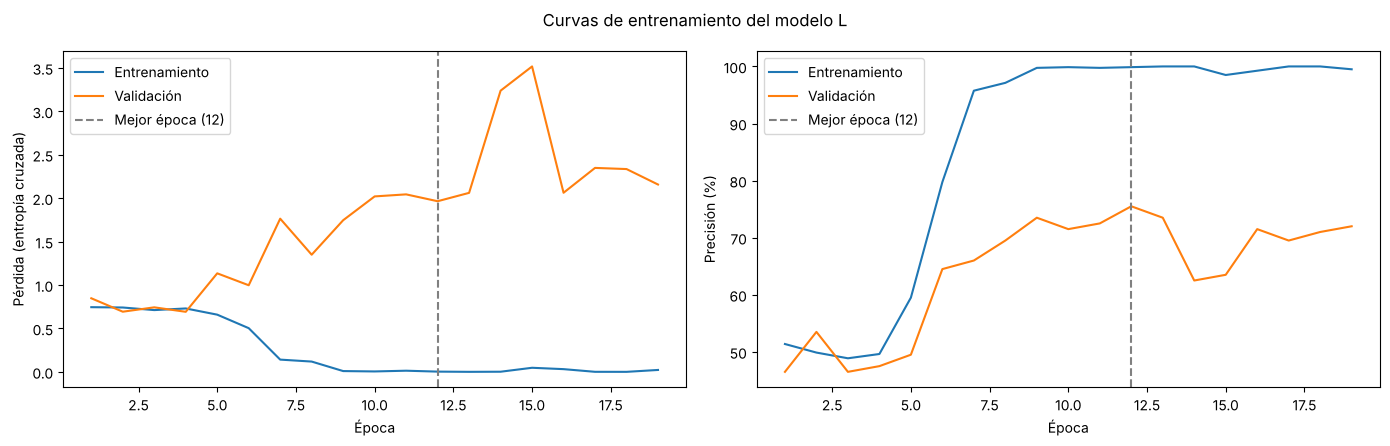

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, xlabel in [(axes[0], 'parámetros', 'Parámetros totales (escala log)'),
                           (axes[1], 'parámetros sin embedding', 'Parámetros sin embedding (escala log)')]:
    ax.plot(results_df[column], results_df['val_acc'], 'o-', label='Validación')
    ax.plot(results_df[column], results_df['test_acc'], 's--', label='Prueba')
    for name, row in results_df.iterrows():
        ax.annotate(name, (row[column], row['test_acc']), textcoords='offset points', xytext=(5, -12))
    ax.set_xscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Precisión (%)')
    ax.legend()
fig.suptitle('Precisión vs. tamaño del modelo (max_length = 128)')
plt.tight_layout()
plt.show()

best_size_name = results_df['val_acc'].idxmax()
print(f"Mejor modelo por validación: {best_size_name}")
plot_history(histories[best_size_name], f'Curvas de entrenamiento del modelo {best_size_name}')

**Tamaño del modelo vs. rendimiento**

- **Las mejoras de arquitectura pesan más que el tamaño.** Con el mismo número de parámetros que el modelo base
  (XS, 0,97 M), la validación sube de 66,5% a 74,0% y la prueba de 65,6% a 70,6%, solo por la máscara de padding,
  la posición, la inicialización y la regularización.
- **Multiplicar por 11 los parámetros no mejora de forma consistente.** De XS a L (de 0,97 M a 10,8 M; de 12 mil
  a 3,2 M sin contar embeddings), la validación queda entre 71,0% y 75,5% y la prueba entre 69,4% y 73,2%. Con 500
  reseñas de prueba el intervalo de confianza del 95% es de ±4 puntos aprox. (±6 con las 200 de validación), así
  que estas diferencias son del orden del ruido. El costo sí crece: L tarda 300 s contra 11 s de XS.
- **El cuello de botella son los datos, no la capacidad.** Con 800 reseñas los modelos memorizan el entrenamiento
  en pocas épocas (el base y el del bonus llegan a ~100%); un modelo más grande tiene más capacidad para memorizar,
  pero no hay más patrones generalizables que aprender. El mejor por validación fue L (75,5% en validación,
  71,2% en prueba), aunque en prueba lo supera M (73,2%): otra muestra de que las diferencias están dentro del
  ruido.

## Análisis de Resultados

### 5: Evaluación en el Conjunto de Test

- [x] Comparar el rendimiento del modelo con muestras de prueba de diferentes longitudes
- [x] Bonus: alcanzar una precisión superior al 90%. Es posible que debas incrementar el numero de parámetros y que debas implementar la atención múltiple AutoAtención y multicapa para lograr esto (libro capítulo 12.3.3).

Modelo base provisto -> Test Accuracy: 65.60%

              precision    recall  f1-score   support

    Negativo      0.633     0.715     0.672       246
    Positivo      0.685     0.598     0.639       254

    accuracy                          0.656       500
   macro avg      0.659     0.657     0.655       500
weighted avg      0.659     0.656     0.655       500



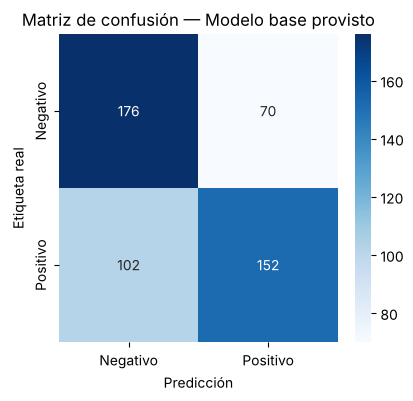

Modelo L -> Test Accuracy: 71.20%

              precision    recall  f1-score   support

    Negativo      0.699     0.728     0.713       246
    Positivo      0.725     0.697     0.711       254

    accuracy                          0.712       500
   macro avg      0.712     0.712     0.712       500
weighted avg      0.713     0.712     0.712       500



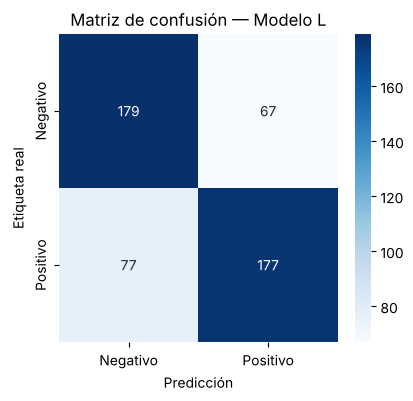

In [21]:
from sklearn.metrics import confusion_matrix, classification_report


def predict_loader(model, loader):
    """Devuelve etiquetas reales, predicciones y probabilidad de 'Positivo' para todo el loader."""
    model.eval()
    y_true, y_pred, p_pos = [], [], []
    with torch.no_grad():
        for batch_texts, batch_labels in loader:
            probs = F.softmax(model(batch_texts.to(device)), dim=1).cpu()
            y_true.extend(batch_labels.tolist())
            y_pred.extend(probs.argmax(dim=1).tolist())
            p_pos.extend(probs[:, 1].tolist())
    return np.array(y_true), np.array(y_pred), np.array(p_pos)


def show_test_results(model, loader, title):
    y_true, y_pred, p_pos = predict_loader(model, loader)
    print(f'{title} -> Test Accuracy: {100 * (y_true == y_pred).mean():.2f}%\n')
    print(classification_report(y_true, y_pred, target_names=['Negativo', 'Positivo'], digits=3))
    cm = confusion_matrix(y_true, y_pred)  # filas: etiqueta real, columnas: predicción
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negativo', 'Positivo'], yticklabels=['Negativo', 'Positivo'])
    plt.xlabel('Predicción')
    plt.ylabel('Etiqueta real')
    plt.title(f'Matriz de confusión — {title}')
    plt.show()
    return y_true, y_pred, p_pos


# Test loop (el test_loader original, batch_size=1)
y_true_base, y_pred_base, p_base = show_test_results(model, test_loader, 'Modelo base provisto')
best_size_model = trained_models[best_size_name]
y_true_best, y_pred_best, p_best = show_test_results(best_size_model, test_loader, f'Modelo {best_size_name}')

### Precisión según la longitud de la reseña

Las reseñas de prueba se dividen en cuatro grupos de igual tamaño (cuartiles) según su cantidad de palabras.
Para cada grupo se reporta la precisión y el porcentaje de reseñas que quedaron truncadas con `max_length`.

--- Base (provisto) (max_length = 128) ---
                     n  precisión %  truncadas %
tramo                                           
37–120 palabras    127         66.9         33.9
121–172 palabras   123         69.1        100.0
173–277 palabras   125         62.4        100.0
278–1014 palabras  125         64.0        100.0 

--- L (max_length = 128) ---
                     n  precisión %  truncadas %
tramo                                           
37–120 palabras    127         77.2         33.9
121–172 palabras   123         73.2        100.0
173–277 palabras   125         68.8        100.0
278–1014 palabras  125         65.6        100.0 



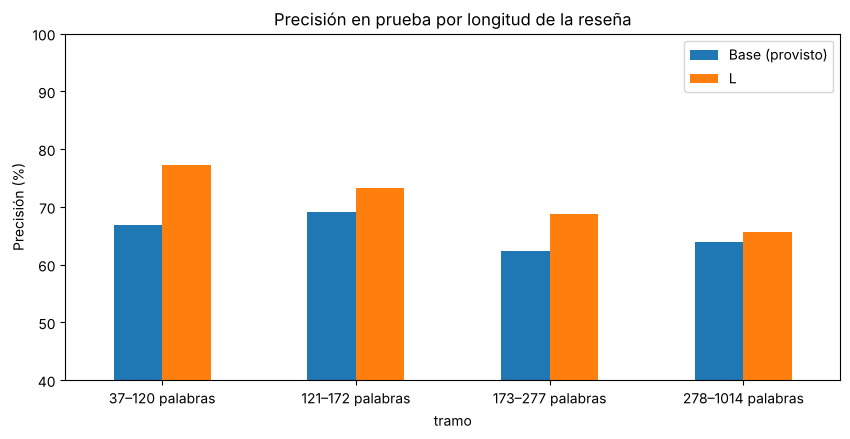

In [22]:
test_texts = [dataset.texts[i] for i in test_dataset.indices]
test_words = np.array([word_count(t) for t in test_texts])
test_subwords = np.array([simple_tokenizer.count_subwords(t) for t in test_texts])
length_bins = pd.qcut(test_words, q=4)
length_bins = length_bins.rename_categories(
    [f'{int(max(c.left, 0)) + 1}–{int(c.right)} palabras' for c in length_bins.categories])


def accuracy_by_length(y_true, y_pred, max_len):
    df = pd.DataFrame({'tramo': length_bins, 'correcto': y_true == y_pred, 'truncada': test_subwords > max_len})
    table = df.groupby('tramo', observed=True).agg(n=('correcto', 'size'), precision=('correcto', 'mean'),
                                                   truncadas=('truncada', 'mean'))
    table[['precision', 'truncadas']] *= 100
    return table.round(1)


length_tables = {
    'Base (provisto)': accuracy_by_length(y_true_base, y_pred_base, max_length),
    best_size_name: accuracy_by_length(y_true_best, y_pred_best, max_length),
}
for name, table in length_tables.items():
    print(f"--- {name} (max_length = {max_length}) ---")
    print(table.rename(columns={'precision': 'precisión %', 'truncadas': 'truncadas %'}), '\n')

pd.DataFrame({name: t['precision'] for name, t in length_tables.items()}).plot.bar(figsize=(10, 4.5), rot=0)
plt.ylabel('Precisión (%)')
plt.ylim(40, 100)
plt.title('Precisión en prueba por longitud de la reseña')
plt.show()

**Precisión según la longitud.** Con `max_length = 128` la precisión cae a medida que la reseña es más larga: en L
baja de 77,2% en el cuartil más corto a 65,6% en el más largo (en el modelo base la tendencia es más débil:
de 66,9% a 64,0%). El primer
cuartil es el único en que una parte de las reseñas cabe completa (solo el 34% se trunca); en los demás se trunca
el 100% y el modelo ve solo el comienzo, que en una reseña larga suele ser el resumen de la trama, mientras el
veredicto suele aparecer al final.

### Bonus: atención multi-cabeza, varias capas y contexto más largo

Con `max_length = 128` la gran mayoría de las reseñas se truncan, así que el modelo no ve gran parte del texto.
Para el bonus se vuelve a crear el conjunto de datos con `max_length = 512` (mismas reseñas y misma partición,
porque `random_split` usa la misma semilla), y se entrena un `TransformerClassifier` con **atención multi-cabeza
(4 cabezas) y 2 capas**, dropout 0,3, *weight decay* 0,1 y batch de 16. La configuración se eligió en pruebas
preliminares por precisión de **validación** (se probaron dimensiones 64 y 128, dropout 0,2–0,4, tasas de
aprendizaje 5·10⁻⁴–2·10⁻³, batch 8–32 y `max_length` 256/512; todas quedaron entre 74 y 79% en validación).

Epoch:  1 | Training Loss: 0.6979, Training Acc: 52.38% | Validation Loss: 0.6869, Validation Accuracy: 55.50%  <- mejor


Epoch:  2 | Training Loss: 0.6967, Training Acc: 55.88% | Validation Loss: 0.6756, Validation Accuracy: 67.00%  <- mejor


Epoch:  3 | Training Loss: 0.6265, Training Acc: 64.50% | Validation Loss: 0.5863, Validation Accuracy: 68.00%  <- mejor


Epoch:  4 | Training Loss: 0.2416, Training Acc: 91.75% | Validation Loss: 1.2598, Validation Accuracy: 66.00%


Epoch:  5 | Training Loss: 0.1352, Training Acc: 95.50% | Validation Loss: 1.3821, Validation Accuracy: 67.00%


...

Epoch: 13 | Training Loss: 0.0007, Training Acc: 100.00% | Validation Loss: 1.6413, Validation Accuracy: 73.50%


Epoch: 14 | Training Loss: 0.0006, Training Acc: 100.00% | Validation Loss: 1.6608, Validation Accuracy: 74.00%


Epoch: 15 | Training Loss: 0.0005, Training Acc: 100.00% | Validation Loss: 1.6774, Validation Accuracy: 74.50%


Epoch: 16 | Training Loss: 0.0005, Training Acc: 100.00% | Validation Loss: 1.6828, Validation Accuracy: 73.50%


Epoch: 17 | Training Loss: 0.0005, Training Acc: 100.00% | Validation Loss: 1.7066, Validation Accuracy: 74.50%
Early stopping en la época 17: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 10: Validation Loss 1.4570, Validation Accuracy 76.50%


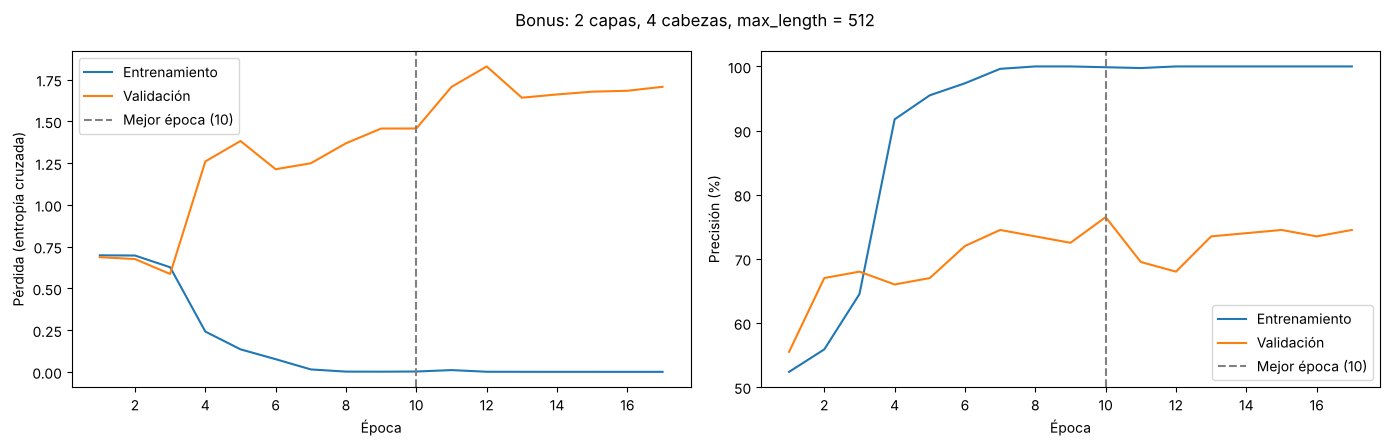

,max_length,embed_dim,capas,cabezas,parámetros,parámetros sin embedding,mejor época,val_acc,test_acc,tiempo (s)
modelo,,,,,,,,,,
Base (provisto),128,32,1,1,971714,11714,11,66.5,65.6,NaN
XS,128,32,1,1,971714,11714,6,74.0,70.6,10.9
S,128,64,2,4,2020098,100098,4,71.0,69.4,26.8
M,128,128,2,4,4236802,396802,8,75.0,73.2,64.9
L,128,256,4,8,10839554,3159554,12,75.5,71.2,300.3
Bonus,512,64,2,4,2020098,100098,10,76.5,78.0,251.0


In [23]:
max_length_long = 512
dataset_long = IMDBDataset(simple_tokenizer, max_length=max_length_long)
train_long, val_long, test_long = random_split(
    dataset_long, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(random_seed))
assert test_long.indices == test_dataset.indices, "La partición de prueba debe ser la misma"

train_loader_long = DataLoader(train_long, batch_size=16, shuffle=True)
val_loader_long = DataLoader(val_long, batch_size=8, shuffle=False)
test_loader_long = DataLoader(test_long, batch_size=1, shuffle=False)
test_eval_loader_long = DataLoader(test_long, batch_size=64, shuffle=False)

bonus_config = dict(embed_dim=64, hidden_dim=256, num_layers=2, num_heads=4, dropout=0.3, lr=1e-3, weight_decay=0.1)
torch.manual_seed(random_seed)
bonus_model = TransformerClassifier(vocab_size, bonus_config['embed_dim'], bonus_config['hidden_dim'], num_classes,
                                    num_layers=bonus_config['num_layers'], num_heads=bonus_config['num_heads'],
                                    max_length=max_length_long, dropout=bonus_config['dropout'])
start = time.time()
history_bonus = train_model(bonus_model, train_loader_long, val_loader_long, epochs=40, lr=bonus_config['lr'],
                            weight_decay=bonus_config['weight_decay'])
bonus_seconds = time.time() - start
plot_history(history_bonus, f'Bonus: {bonus_config["num_layers"]} capas, {bonus_config["num_heads"]} cabezas, max_length = {max_length_long}')

results_df.loc['Bonus'] = pd.Series(summarize('Bonus', bonus_model, history_bonus, bonus_seconds, max_length_long,
                                              bonus_config['num_layers'], bonus_config['num_heads'],
                                              bonus_config['embed_dim'])).drop('modelo')
results_df

Bonus -> Test Accuracy: 78.00%

              precision    recall  f1-score   support

    Negativo      0.766     0.797     0.781       246
    Positivo      0.795     0.764     0.779       254

    accuracy                          0.780       500
   macro avg      0.780     0.780     0.780       500
weighted avg      0.781     0.780     0.780       500



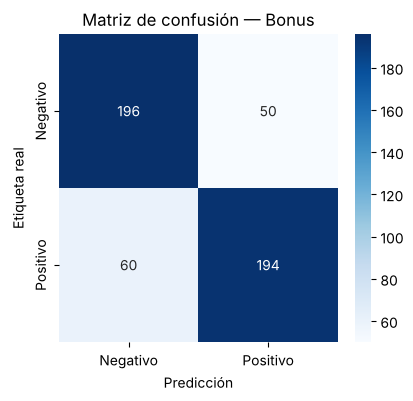

¿Supera el 90%? No (78.00%)

--- Bonus (max_length = 512) ---
                     n  precisión %  truncadas %
tramo                                           
37–120 palabras    127         78.7          0.0
121–172 palabras   123         77.2          0.0
173–277 palabras   125         80.0          0.0
278–1014 palabras  125         76.0         43.2


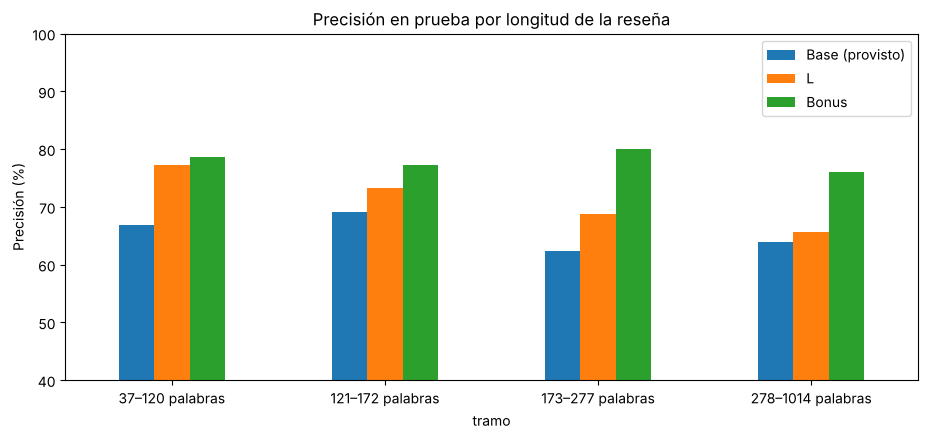

In [24]:
y_true_bonus, y_pred_bonus, p_bonus = show_test_results(bonus_model, test_loader_long, 'Bonus')
bonus_acc = 100 * (y_true_bonus == y_pred_bonus).mean()
print(f"¿Supera el 90%? {'Sí' if bonus_acc > 90 else 'No'} ({bonus_acc:.2f}%)")

length_tables['Bonus'] = accuracy_by_length(y_true_bonus, y_pred_bonus, max_length_long)
print(f"\n--- Bonus (max_length = {max_length_long}) ---")
print(length_tables['Bonus'].rename(columns={'precision': 'precisión %', 'truncadas': 'truncadas %'}))

pd.DataFrame({name: t['precision'] for name, t in length_tables.items()}).plot.bar(figsize=(11, 4.5), rot=0)
plt.ylabel('Precisión (%)')
plt.ylim(40, 100)
plt.title('Precisión en prueba por longitud de la reseña')
plt.show()

**Resultado del bonus: 78,0% en prueba (76,5% en validación). No se alcanza el 90%.**

- **Ver más texto es lo que más ayudó.** El modelo del bonus tiene el mismo tamaño que S (2,0 M parámetros) y
  sube de 69,4% a 78,0% en prueba solo por usar 512 fragmentos en vez de 128. Con 512, la precisión queda pareja
  en todos los tramos de longitud (76–80%), incluso en el cuartil más largo, donde todavía se trunca el 43%.
- Las dos clases quedan equilibradas (precisión y recall entre 0,76 y 0,80 en ambas).
- **¿Por qué no 90%?** Entrenando desde cero con 800 reseñas, el modelo llega a 99,6% en entrenamiento en la época 7
  y desde ahí solo memoriza. En las pruebas preliminares ninguna configuración (dimensión 64/128, 1–4 capas,
  dropout 0,2–0,4, distintas tasas de aprendizaje, batch y largo de contexto) superó el 79% en validación. Los
  resultados sobre 90% en IMDB usan las 25.000 reseñas de entrenamiento o Transformers pre-entrenados como BERT.

### Referencia: un modelo lineal clásico con los mismos datos

Para dimensionar qué tan difícil es la tarea con solo 800 reseñas, se entrena una regresión logística sobre
TF-IDF de palabras y bigramas (sin redes neuronales), con las mismas particiones. El parámetro de regularización
`C` se elige con el conjunto de validación.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

split_texts = lambda subset: [dataset.texts[i] for i in subset.indices]
split_labels = lambda subset: [dataset.labels[i] for i in subset.indices]

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(split_texts(train_dataset))
X_val, X_test = vectorizer.transform(split_texts(val_dataset)), vectorizer.transform(split_texts(test_dataset))

val_scores = {C: LogisticRegression(C=C, max_iter=2000).fit(X_train, split_labels(train_dataset))
                 .score(X_val, split_labels(val_dataset)) for C in [0.25, 1, 4, 16, 64]}
best_C = max(val_scores, key=val_scores.get)
tfidf_model = LogisticRegression(C=best_C, max_iter=2000).fit(X_train, split_labels(train_dataset))
tfidf_test = 100 * tfidf_model.score(X_test, split_labels(test_dataset))
print(f"TF-IDF + regresión logística (C = {best_C}): validación {100 * val_scores[best_C]:.1f}%, prueba {tfidf_test:.1f}%")
print(f"Mejor Transformer (bonus): prueba {bonus_acc:.1f}%")

TF-IDF + regresión logística (C = 16): validación 81.0%, prueba 84.4%
Mejor Transformer (bonus): prueba 78.0%


### Errores más confiados del modelo final

Se muestran las reseñas de prueba en que el modelo se equivocó con mayor confianza, para entender qué tipo de
reseñas le cuestan.

In [26]:
# El modelo final es el de mayor precisión de validación entre todos los entrenados
trained_models['Bonus'] = bonus_model
final_name = results_df['val_acc'].astype(float).idxmax()
final_model = trained_models[final_name]
final_max_length = int(results_df.loc[final_name, 'max_length'])
final_loader = test_loader_long if final_max_length == max_length_long else test_loader
y_true_final, y_pred_final, p_final = predict_loader(final_model, final_loader)
print(f"Modelo final: {final_name} (max_length = {final_max_length}), "
      f"Test Accuracy: {100 * (y_true_final == y_pred_final).mean():.2f}%\n")

errors = np.where(y_true_final != y_pred_final)[0]
confidence = np.abs(p_final[errors] - 0.5)
class_labels = {0: "Negative", 1: "Positive"}
for i in errors[np.argsort(-confidence)][:6]:
    print(f"Real: {class_labels[y_true_final[i]]} | Predicho: {class_labels[y_pred_final[i]]} "
          f"(P(positivo) = {p_final[i]:.2f}) | {test_words[i]} palabras")
    print(f"   {test_texts[i][:400].replace('<br />', ' ')}...\n")

Modelo final: Bonus (max_length = 512), Test Accuracy: 78.00%

Real: Positive | Predicho: Negative (P(positivo) = 0.00) | 296 palabras
   Smallville episode Justice is the best episode of Smallville ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! It's my favorite episode of Smallville! ! ! ! ! ! !...

Real: Positive | Predicho: Negative (P(positivo) = 0.00) | 210 palabras
   OK...i have seen just about everything....and some are considered classics that shouldn't be ( like all those Halloween movies that suck crap or even Steven king junk).......and some are considered just OK that are really great.....( like carnival of souls )........and then some are just plain ignored............like ( evil ed ) or ( pumpkin head and brain dead "the bud Cort one"

**¿Qué reseñas falla con más confianza?** Las seis son positivas clasificadas como negativas con
P(positivo) ≈ 0,00:

- **Puntuación repetida** (`! ! ! !`, `!!!`, `......`): el modelo la toma como señal negativa (probablemente porque
  abunda en reseñas negativas indignadas), aunque aquí acompañe entusiasmo ("the best episode of Smallville ! ! !",
  "the best movie I`ve ever seen !!!").
- **Reseñas positivas con vocabulario negativo**: "I don't understand", "my confusion", "suck crap", "junk",
  "kill", "worst", "low budget", o que comparan con otra película peor ("no doubt the weakest of the modern
  Scooby Doo..."). El promedio final mezcla todas las palabras y el veredicto positivo queda diluido.
- **Ortografía no estándar** ("appologise", "madnes", "I`ve"), que produce fragmentos poco vistos.

## Despliegue

### 6: Pruebas con Ejemplos Personalizados

- [x] Intenta crear nuevos ejemplos donde el modelo falla al clasificar correctamente el sentimiento.
- [x] Experimenta, describe y explica qué ocurre cuando intentas clasificar una crítica de cine en español utilizando tu modelo de transformador.

In [27]:
def predict(review, model=None, max_len=None):
    """Clasifica una reseña y devuelve (etiqueta, probabilidad de 'Positive')."""
    model = model if model is not None else final_model
    max_len = max_len if max_len is not None else final_max_length
    inputs = simple_tokenizer.encode(review, max_length=max_len)
    inputs = torch.tensor([inputs], dtype=torch.long).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(inputs), dim=1)[0].cpu()
    return class_labels[probs.argmax().item()], probs[1].item()


review = "The movie was amazing"
predicted_label, p_positive = predict(review)
print(f"The predicted class for the text '{review}' is: {predicted_label} (P(positive) = {p_positive:.2f})")

The predicted class for the text 'The movie was amazing' is: Negative (P(positive) = 0.00)


### Casos difíciles en inglés

Se prueban reseñas escritas para estresar al modelo: negaciones, sarcasmo, contraste ("but") y reseñas muy cortas.

In [28]:
custom_reviews = [
    # (reseña, etiqueta esperada, tipo de caso)
    ("The movie was amazing", "Positive", "simple"),
    ("An absolute masterpiece, the acting and the soundtrack were wonderful.", "Positive", "simple"),
    ("This was the worst film I have ever seen, a total waste of time.", "Negative", "simple"),
    ("The movie was not good at all.", "Negative", "negación"),
    ("I didn't hate it. Honestly, it is not bad at all.", "Positive", "doble negación"),
    ("Oh great, another two hours of my life I will never get back. Brilliant.", "Negative", "sarcasmo"),
    ("The actors were great and the photography was beautiful, but the story was so boring that I fell asleep.",
     "Negative", "contraste"),
    ("Everyone told me it was awful and I expected to hate it, but I loved every minute.", "Positive", "giro final"),
    ("Meh.", "Negative", "muy corta"),
    ("10/10", "Positive", "muy corta"),
]

rows = []
for text, expected, case in custom_reviews:
    predicted, p_positive = predict(text)
    rows.append({'reseña': text, 'caso': case, 'esperado': expected, 'predicho': predicted,
                 'P(positive)': round(p_positive, 3), 'correcto': '✓' if predicted == expected else '✗'})
custom_df = pd.DataFrame(rows)
print(f"Aciertos: {(custom_df['correcto'] == '✓').sum()} de {len(custom_df)}")
with pd.option_context('display.max_colwidth', 120):
    display(custom_df)

Aciertos: 5 de 10


,reseña,caso,esperado,predicho,P(positive),correcto
0,The movie was amazing,simple,Positive,Negative,0.000,✗
1,"An absolute masterpiece, the acting and the soundtrack were wonderful.",simple,Positive,Negative,0.000,✗
2,"This was the worst film I have ever seen, a total waste of time.",simple,Negative,Negative,0.000,✓
3,The movie was not good at all.,negación,Negative,Negative,0.000,✓
4,"I didn't hate it. Honestly, it is not bad at all.",doble negación,Positive,Negative,0.000,✗
5,"Oh great, another two hours of my life I will never get back. Brilliant.",sarcasmo,Negative,Positive,1.000,✗
6,"The actors were great and the photography was beautiful, but the story was so boring that I fell asleep.",contraste,Negative,Positive,1.000,✗
7,"Everyone told me it was awful and I expected to hate it, but I loved every minute.",giro final,Positive,Positive,1.000,✓
8,Meh.,muy corta,Negative,Negative,0.000,✓
9,10/10,muy corta,Positive,Positive,0.999,✓


**Casos difíciles: 5 de 10 aciertos.** El modelo final falla en casos que una persona resuelve sin problema:

- **Elogios cortos y directos.** "The movie was amazing" y "An absolute masterpiece... wonderful." salen negativas
  con P(positive) ≈ 0,000, aunque `amazing_`, `masterpiece_` y `wonderful_` son fragmentos conocidos. Las reseñas de
  entrenamiento tienen ~210 fragmentos de mediana (la más corta del conjunto de prueba tiene 37 palabras), así que
  un texto de 4–10 palabras está fuera de la distribución que vio el modelo. Con textos cortos tiende a predecir
  negativo: 6 de los 10 ejemplos salen negativos. "10/10" sí sale positiva, probablemente porque esa expresión
  aparece en reseñas positivas del entrenamiento.
- **Sarcasmo** ("Oh great... Brilliant.") y **contraste** ("great... beautiful, but... boring"): salen positivas
  con P > 0,99. El modelo suma la evidencia de las palabras positivas y no entiende la ironía ni que "but" cambie
  cuál parte pesa más.
- **Doble negación** ("I didn't hate it... not bad at all"): sale negativa, porque ve "hate" y "bad".
- Acierta la negación simple ("not good at all"), el giro final ("...but I loved every minute"), "Meh." y "10/10".
- En todos los casos las probabilidades son extremas (≈ 0,000 o ≈ 1,000): el modelo está **sobreconfiado**,
  porque llegó a 100% en entrenamiento.

### Reseñas en español

Se clasifica cada reseña en español junto a su traducción al inglés y se inspecciona cómo la segmenta el
tokenizador.

In [29]:
spanish_reviews = [
    # (español, traducción al inglés, etiqueta esperada)
    ("La película fue maravillosa, la recomiendo totalmente.",
     "The movie was wonderful, I totally recommend it.", "Positive"),
    ("Una película excelente, con actuaciones brillantes y una historia emocionante.",
     "An excellent movie, with brilliant performances and an exciting story.", "Positive"),
    ("Me encantó, es la mejor película del año.",
     "I loved it, it is the best movie of the year.", "Positive"),
    ("Es una película horrible, aburrida y demasiado larga.",
     "It is a horrible movie, boring and way too long.", "Negative"),
    ("Pésima. Los actores son malísimos y el guion no tiene ningún sentido.",
     "Awful. The actors are terrible and the script makes no sense at all.", "Negative"),
    ("Una pérdida de tiempo y de dinero, no la recomiendo.",
     "A waste of time and money, I do not recommend it.", "Negative"),
]

rows = []
for spanish, english, expected in spanish_reviews:
    pred_es, p_es = predict(spanish)
    pred_en, p_en = predict(english)
    rows.append({'reseña en español': spanish, 'esperado': expected,
                 'pred. español': pred_es, 'P(pos) español': round(p_es, 3),
                 'pred. inglés': pred_en, 'P(pos) inglés': round(p_en, 3)})
spanish_df = pd.DataFrame(rows)
print(f"Aciertos en español: {(spanish_df['pred. español'] == spanish_df['esperado']).sum()} de {len(spanish_df)}")
print(f"Aciertos en inglés:  {(spanish_df['pred. inglés'] == spanish_df['esperado']).sum()} de {len(spanish_df)}")
with pd.option_context('display.max_colwidth', 80):
    display(spanish_df)


def segmentation_stats(sentences):
    words = [w for s in sentences for w in simple_tokenizer.tokenize(s)]
    pieces = [simple_tokenizer._apply_bpe_to_word(w) for w in words]
    n_pieces = sum(len(p) for p in pieces)
    n_unk = sum(tok not in simple_tokenizer.vocab for p in pieces for tok in p)
    whole = sum(len(p) == 1 for p in pieces)
    return {'fragmentos por palabra': round(n_pieces / len(words), 2),
            'palabras que son un solo fragmento %': round(100 * whole / len(words), 1),
            'fragmentos [UNK] %': round(100 * n_unk / n_pieces, 1)}


print()
print(pd.DataFrame({'español': segmentation_stats([s for s, _, _ in spanish_reviews]),
                    'inglés': segmentation_stats([e for _, e, _ in spanish_reviews])}))

for sentence in [spanish_reviews[0][0], spanish_reviews[0][1], spanish_reviews[4][0]]:
    ids = [i for i in simple_tokenizer.encode(sentence, max_length=64) if i != 0]
    print(f"\n{sentence}\n  -> {[simple_tokenizer.reverse_vocab[i] for i in ids]}")

Aciertos en español: 4 de 6
Aciertos en inglés:  6 de 6


,reseña en español,esperado,pred. español,P(pos) español,pred. inglés,P(pos) inglés
0,"La película fue maravillosa, la recomiendo totalmente.",Positive,Negative,0.011,Positive,1.0
1,"Una película excelente, con actuaciones brillantes y una historia emocionante.",Positive,Positive,1.000,Positive,1.0
2,"Me encantó, es la mejor película del año.",Positive,Negative,0.000,Positive,1.0
3,"Es una película horrible, aburrida y demasiado larga.",Negative,Negative,0.000,Negative,0.0
4,Pésima. Los actores son malísimos y el guion no tiene ningún sentido.,Negative,Negative,0.000,Negative,0.0
5,"Una pérdida de tiempo y de dinero, no la recomiendo.",Negative,Negative,0.002,Negative,0.0



                                      español  inglés
fragmentos por palabra                   2.07     1.0
palabras que son un solo fragmento %    55.20   100.0
fragmentos [UNK] %                       0.00     0.0

La película fue maravillosa, la recomiendo totalmente.
  -> ['la_', 'pel', 'í', 'cul', 'a_', 'fu', 'e_', 'mar', 'av', 'il', 'lo', 'sa_', ',_', 'la_', 're', 'com', 'i', 'en', 'do_', 'total', 'ment', 'e_', '._']

The movie was wonderful, I totally recommend it.
  -> ['the_', 'movie_', 'was_', 'wonderful_', ',_', 'i_', 'totally_', 'recommend_', 'it_', '._']

Pésima. Los actores son malísimos y el guion no tiene ningún sentido.
  -> ['p', 'é', 'sim', 'a_', '._', 'los_', 'act', 'ores_', 'son_', 'mal', 'í', 'si', 'mos_', 'y_', 'el_', 'gu', 'ion_', 'no_', 'ti', 'ene_', 'n', 'ing', 'ú', 'n_', 'senti', 'do_', '._']


**¿Qué pasa con las reseñas en español?** El tokenizador no falla de forma visible: con BPE no aparece ningún
`[UNK]`, porque cualquier palabra se puede armar con fragmentos o con caracteres sueltos. El problema es que esas
piezas no tienen significado para el modelo:

- Se usan **2,07 fragmentos por palabra** en español contra 1,0 en la traducción al inglés, y solo el 55% de las
  palabras en español queda como un fragmento único. Casi todas son palabras funcionales o puntuación (`la`, `el`,
  `de`, `no`, `y`, `,`, `.`).
- Las palabras con sentimiento quedan partidas: `maravillosa` → `mar|av|il|lo|sa_`, `excelente` → `exc|el|ente_`,
  `aburrida` → `a|bur|ri|da_`, `pésima` → `p|é|sim|a_`. Los embeddings de esos fragmentos se aprendieron en
  palabras inglesas sin relación con el sentimiento. La única palabra con sentimiento compartida es `horrible`,
  cognado que sí es un fragmento completo.
- El 4 de 6 parece aceptable, pero es casualidad. De las 3 reseñas positivas solo acierta una; "maravillosa" y
  "me encantó... la mejor" salen negativas con P(positive) ≤ 0,011. Las 3 negativas "aciertan", probablemente por el mismo
  sesgo hacia negativo que el modelo muestra con textos cortos.
- Las mismas reseñas traducidas al inglés: **6 de 6**, con alta confianza. El modelo no "sabe" español: el
  vocabulario y los embeddings se aprendieron solo con reseñas en inglés.

## Conclusiones

Analiza los resultados obtenidos:

- ¿Qué tipo de reseñas fueron más difíciles de clasificar para el modelo? ¿A qué crees que se debe?
- ¿Qué mejoras podrías proponer para el modelo o el proceso de entrenamiento?
- ¿Qué sucede cuando pruebas el modelo con texto en español?

### Resumen de resultados (500 reseñas de prueba)

| Modelo | `max_length` | Parámetros | Validación | Prueba |
|---|---|---|---|---|
| Base provisto, 1 época (notebook original) | 128 | 0,97 M | 53,5% | 53,0% |
| Base provisto + early stopping | 128 | 0,97 M | 66,5% | 65,6% |
| Mejor por tamaño según validación (L: 256 dim, 4 capas, 8 cabezas) | 128 | 10,8 M | 75,5% | 71,2% |
| **Bonus** (64 dim, 2 capas, 4 cabezas) | 512 | 2,0 M | 76,5% | **78,0%** |
| Referencia: TF-IDF + regresión logística | — | — | 81,0% | 84,4% |

Las cifras cambian algunos puntos entre ejecuciones, porque el entrenamiento con varios hilos (CPU) o en GPU no
es determinista bit a bit. En otra ejecución idéntica, el bonus volvió a dar 78,0% y el modelo base, 65,0%.

**¿Qué tipo de reseñas fueron más difíciles de clasificar? ¿A qué se debe?**

- **Las largas, cuando se truncan.** Con 128 fragmentos la precisión baja de 77% a 66% del cuartil más corto al
  más largo, porque el veredicto suele ir al final. Con 512 la diferencia desaparece (76–80% en todos los tramos).
- **Las muy cortas.** Un texto de 1–10 palabras está fuera de la distribución de entrenamiento (la mediana es de
  ~210 fragmentos): las predicciones son extremas y tienden a negativo ("The movie was amazing" → negativo).
- **Las que mezclan vocabulario positivo y negativo**: contraste con "but", sarcasmo, doble negación, reseñas
  positivas que critican algo. El modelo se comporta casi como una bolsa de palabras: el promedio final suma la
  evidencia de todas las palabras y no distingue cuál parte manda.
- **Las de estilo no estándar**: puntuación repetida (`!!!!`, `....`), que el modelo asocia con reseñas negativas,
  y faltas de ortografía.
- **La causa de fondo es la falta de datos.** Con 800 reseñas hay que aprender desde cero 30.000 embeddings, la
  mayoría de fragmentos vistos pocas veces. El modelo memoriza el entrenamiento (~100%) en pocas épocas y queda
  sobreconfiado. Por eso un modelo lineal TF-IDF, con mucho menos para aprender, supera al Transformer
  (84,4% vs. 78,0%).

**¿Qué mejoras se pueden proponer?**

- **Más datos etiquetados.** El dataset tiene 50.000 reseñas etiquetadas; es la mejora más directa.
- **Pre-entrenamiento y ajuste fino** (libro, cap. 12.5): pre-entrenar el encoder con *masked language modeling*
  sobre las 50.000 reseñas sin etiqueta del split `unsupervised`, o partir de un modelo pre-entrenado (BERT,
  DistilBERT). Es el camino realista para superar el 90%.
- **Embeddings de palabras pre-entrenados** (word2vec, GloVe), para no aprender 30.000 vectores desde cero.
- **Un mejor tokenizador.** `build_vocab` usa las primeras 3.000 reseñas, que en el orden del dataset son todas
  negativas. Conviene muestrear al azar y usar más texto. Separar la puntuación y quitar los `<br />` ya ayudó: en
  las pruebas preliminares, con la misma configuración, la validación subió de 75,0% a 79,0% (y la prueba, de
  77,8% a 79,4%).
- **Entrenamiento.** Monitorear la precisión en lugar de la pérdida (ya incluido; con la pérdida se restauraban
  épocas con ~55–60%), usar *warm-up* en modelos profundos (ya incluido), y agregar *label smoothing* o calibración
  para la sobreconfianza, *dropout* de palabras o aumento de datos (por ejemplo, retraducción), y validación
  cruzada, ya que 200 reseñas de validación dejan ±6 puntos de ruido al elegir hiperparámetros.
- **Arquitectura.** Usar un token `[CLS]` o *pooling* por atención en vez del promedio, para que el modelo pueda
  darle más peso al veredicto que al resumen de la trama.

**¿Qué sucede cuando se prueba el modelo con texto en español?**

El modelo no puede clasificar español de forma confiable. BPE evita los `[UNK]`, pero divide las palabras en
fragmentos sin significado para el modelo (2,07 fragmentos por palabra vs. 1,0 en inglés; `maravillosa` →
`mar|av|il|lo|sa_`), cuyos embeddings se aprendieron en palabras inglesas sin relación con el sentimiento. Las
predicciones son muy confiadas pero arbitrarias: acierta 4 de 6, aunque solo 1 de las 3 positivas, y las
negativas probablemente "aciertan" por el sesgo hacia negativo con textos cortos. Solo funcionan los cognados que
coinciden exactamente con palabras en inglés (`horrible`). Las mismas reseñas traducidas al inglés se clasifican
6 de 6. Para manejar español habría que entrenar con datos en español o usar un modelo multilingüe pre-entrenado
(por ejemplo, mBERT o XLM-R), cuyo vocabulario y embeddings cubren varios idiomas.